In [ ]:
# Mengimpor librari Python
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


Pada latihan ini saya melakukan pemodelan klasifikasi penyakit jantung. Tujuannya adalah memprediksi apakah seseorang termasuk kelas memiliki penyakit jantung atau tidak berdasarkan karakteristik kesehatan yang tersedia pada dataset

# Mengunggah dan menampilkan sejumlah data

In [ ]:
# Mengunggah data
from google.colab import files
upoaded = files.upload()

# Membaca data dari direktori komputer
dataset = pd.read_csv('heart.csv')

# Menampilkan variabel dan ukuran data
display(dataset)

Saving heart.csv to heart.csv


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,NaN,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49.0,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37.0,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48.0,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54.0,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45.0,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68.0,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57.0,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57.0,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [ ]:
# Mengidentifikasi variabel yang awalnya kategorikal
# (Sebelum konversi, variabel kategorikal memiliki tipe 'object')
original_categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

print("Nilai unik untuk setiap variabel kategorikal (setelah konversi):")
for col in original_categorical_cols:
    if col in dataset.columns:
        print(f"\nVariabel: {col}")
        print(dataset[col].unique())
    else:
        print(f"\nVariabel: {col} not found in dataset.")

Nilai unik untuk setiap variabel kategorikal (setelah konversi):

Variabel: Sex
['M' 'F' nan]

Variabel: ChestPainType
['ATA' 'NAP' 'ASY' 'TA']

Variabel: RestingECG
['Normal' 'ST' 'LVH']

Variabel: ExerciseAngina
['N' 'Y']

Variabel: ST_Slope
['Up' 'Flat' 'Down']


# Menampilkan jenis data setiap variabel

In [ ]:
print(dataset.dtypes)

Age               float64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object


Berdasarkan jenis data setiap variabel:

*   **Age (float64):** Variabel ini memiliki tipe data float64, yang menunjukkan bahwa usia direpresentasikan sebagai angka desimal. Namun, perlu diperhatikan bahwa ada nilai yang hilang (NaN) seperti yang terlihat dari output `dataset.describe()`, yang perlu ditangani sebelum analisis lebih lanjut.
*   **Sex (object):** Variabel ini memiliki tipe data object, yang menunjukkan bahwa jenis kelamin direpresentasikan sebagai string (teks). Ini adalah variabel kategorikal.
*   **ChestPainType (object):** Variabel ini juga memiliki tipe data object, menunjukkan jenis nyeri dada direpresentasikan sebagai string. Ini adalah variabel kategorikal.
*   **RestingBP (int64):** Variabel ini memiliki tipe data int64, menunjukkan tekanan darah saat istirahat direpresentasikan sebagai bilangan bulat. Ini adalah variabel numerikal.
*   **Cholesterol (int64):** Variabel ini memiliki tipe data int64, menunjukkan kadar kolesterol direpresentasikan sebagai bilangan bulat. Ini adalah variabel numerikal.
*   **FastingBS (int64):** Variabel ini memiliki tipe data int64, menunjukkan gula darah puasa direpresentasikan sebagai bilangan bulat. Ini adalah variabel biner (0 atau 1).
*   **RestingECG (object):** Variabel ini memiliki tipe data object, menunjukkan hasil elektrokardiogram saat istirahat direpresentasikan sebagai string. Ini adalah variabel kategorikal.
*   **MaxHR (int64):** Variabel ini memiliki tipe data int64, menunjukkan detak jantung maksimum direpresentasikan sebagai bilangan bulat. Ini adalah variabel numerikal.
*   **ExerciseAngina (object):** Variabel ini memiliki tipe data object, menunjukkan adanya angina saat berolahraga direpresentasikan sebagai string. Ini adalah variabel biner (Yes atau No).
*   **Oldpeak (float64):** Variabel ini memiliki tipe data float64, menunjukkan depresi ST saat istirahat relatif terhadap latihan direpresentasikan sebagai angka desimal. Ini adalah variabel numerikal.
*   **ST_Slope (object):** Variabel ini memiliki tipe data object, menunjukkan kemiringan segmen ST selama latihan puncak direpresentasikan sebagai string. Ini adalah variabel kategorikal.
*   **HeartDisease (int64):** Variabel ini memiliki tipe data int64, menunjukkan keberadaan penyakit jantung direpresentasikan sebagai bilangan bulat. Ini adalah variabel target biner (0 atau 1).

Memahami jenis data ini penting untuk memilih metode analisis dan visualisasi yang tepat. Variabel kategorikal memerlukan penanganan yang berbeda dibandingkan variabel numerikal.

**Menampilkan nilai variabel yang kosong**

In [ ]:
# Menampilkan jumlah nilai kosong per variabel
print(dataset.isnull().sum())

Age                7
Sex               10
ChestPainType      0
RestingBP          0
Cholesterol        0
FastingBS          0
RestingECG         0
MaxHR              0
ExerciseAngina     0
Oldpeak            0
ST_Slope           0
HeartDisease       0
dtype: int64


**Menangani variabel dengan nilai kosong**

In [ ]:
# Mengganti nilai kosong pada kolom 'Age' dengan nilai rata-ratanya
dataset['Age'].fillna(dataset['Age'].mean(), inplace=True)

# Menghapus baris dengan nilai kosong pada kolom 'Sex'
dataset.dropna(subset=['Sex'], inplace=True)

# Memverifikasi bahwa nilai kosong pada kolom 'Age' dan 'Sex' telah terisi/dihapus
print("Jumlah nilai kosong pada kolom 'Age' setelah imputasi:", dataset['Age'].isnull().sum())
print("Jumlah nilai kosong pada kolom 'Sex' setelah penghapusan:", dataset['Sex'].isnull().sum())

Jumlah nilai kosong pada kolom 'Age' setelah imputasi: 0
Jumlah nilai kosong pada kolom 'Sex' setelah penghapusan: 0


/tmp/ipykernel_576/1987403989.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Age'].fillna(dataset['Age'].mean(), inplace=True)


In [ ]:
# Menampilkan jumlah nilai kosong per variabel
print(dataset.isnull().sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


**Mendeteksi duplikasi data**

In [ ]:
# Menghitung jumlah data duplikat
duplicate_rows = dataset.duplicated().sum()

# Menampilkan jumlah data duplikat
print("Jumlah data duplikat:", duplicate_rows)

Jumlah data duplikat: 0


**Mendeteksi variabel yang nilainya sama**

In [ ]:
# Mendeteksi variabel yang nilainya sama
same_value_cols = []
for col in dataset.columns:
    if dataset[col].nunique() == 1:
        same_value_cols.append(col)

# Menampilkan variabel yang nilainya sama (jika ada)
if same_value_cols:
    print("Variabel dengan nilai yang sama untuk semua baris:", same_value_cols)
else:
    print("Tidak ada variabel dengan nilai yang sama untuk semua baris.")

Tidak ada variabel dengan nilai yang sama untuk semua baris.


**Menampilkan statistik deskriptif dari data input**

In [ ]:
display(dataset.describe())

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,908.000000,908.000000,908.000000,908.000000,908.000000,908.000000,908.000000
mean,54.114111,132.397577,199.055066,0.232379,136.808370,0.886784,0.553965
std,12.990253,18.556611,109.443744,0.422582,25.483563,1.067719,0.497353
min,0.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,175.000000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,177.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Berdasarkan statistik deskriptif dari data input (`dataset.describe()`):

**Variabel Numerikal:**

*   **Age:** Usia rata-rata dalam dataset adalah sekitar 54.1 tahun, dengan standar deviasi sekitar 13 tahun. Rentang usia cukup luas, dari minimum 0 (kemungkinan data yang salah atau outlier) hingga maksimum 177 (kemungkinan data yang salah atau outlier). Nilai kuartil pertama (25%) adalah 47 tahun, median (50%) adalah 54 tahun, dan kuartil ketiga (75%) adalah 60 tahun. Terdapat 911 data usia yang valid, menunjukkan ada beberapa nilai yang hilang.
*   **RestingBP (Tekanan Darah Saat Istirahat):** Tekanan darah rata-rata saat istirahat adalah sekitar 132.4 mmHg, dengan standar deviasi sekitar 18.5 mmHg. Rentangnya dari 0 (kemungkinan data yang salah atau outlier) hingga 200 mmHg. Sebagian besar data berada di kisaran normal, tetapi ada beberapa nilai yang tinggi.
*   **Cholesterol:** Kadar kolesterol rata-rata adalah sekitar 198.8 mg/dL, dengan standar deviasi sekitar 109.4 mg/dL. Rentangnya sangat luas, dari 0 hingga 603 mg/dL. Nilai 0 untuk kolesterol kemungkinan merupakan data yang hilang atau tidak valid.
*   **MaxHR (Detak Jantung Maksimum):** Detak jantung maksimum rata-rata adalah sekitar 136.8 bpm, dengan standar deviasi sekitar 25.5 bpm. Rentangnya dari 60 hingga 202 bpm.
*   **Oldpeak:** Rata-rata Oldpeak adalah sekitar 0.89, dengan standar deviasi sekitar 1.07. Rentangnya dari -2.6 hingga 6.2.

**Variabel Biner (FastingBS, HeartDisease):**

*   **FastingBS (Gula Darah Puasa > 120 mg/dL):** Rata-rata 0.233 menunjukkan bahwa sekitar 23.3% individu dalam dataset memiliki gula darah puasa lebih dari 120 mg/dL (nilai 1).
*   **HeartDisease:** Rata-rata 0.554 menunjukkan bahwa sekitar 55.4% individu dalam dataset memiliki penyakit jantung (nilai 1).

**Kesimpulan dari Statistik Deskriptif:**

*   Dataset ini berisi informasi tentang individu dengan berbagai karakteristik terkait kesehatan jantung.
*   Terdapat beberapa nilai yang hilang atau outlier dalam variabel 'Age', 'RestingBP', dan 'Cholesterol' yang perlu ditangani.
*   Distribusi variabel numerikal bervariasi, dengan beberapa variabel menunjukkan rentang yang luas dan potensi outlier.
*   Proporsi individu dengan gula darah puasa tinggi dan penyakit jantung cukup signifikan dalam dataset ini.

Analisis statistik deskriptif ini memberikan gambaran awal tentang sebaran data dan potensi masalah kualitas data yang perlu ditangani sebelum analisis lebih mendalam.

**Menampilkan visualisasi variabel Kategorikal (Sex, ChestPainType, RestingECG, ExerciseAngina, dan ST_SLope)**

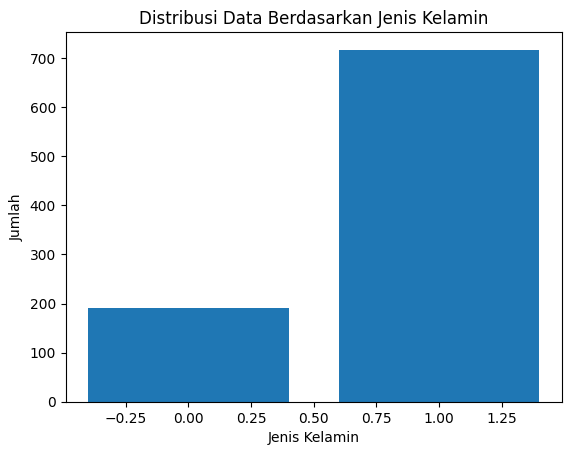

In [ ]:
# prompt: Menampilkan bar chart variabel Sex. Berikan judul bar chart "Distribusi Data Berdasarkan Jenis Kelamin"

import matplotlib.pyplot as plt

# Menghitung jumlah data untuk setiap jenis kelamin
sex_counts = dataset['Sex'].value_counts()


# Membuat bar chart
plt.bar(sex_counts.index, sex_counts.values)
plt.title('Distribusi Data Berdasarkan Jenis Kelamin')
plt.xlabel('Jenis Kelamin')
plt.ylabel('Jumlah')
plt.show()

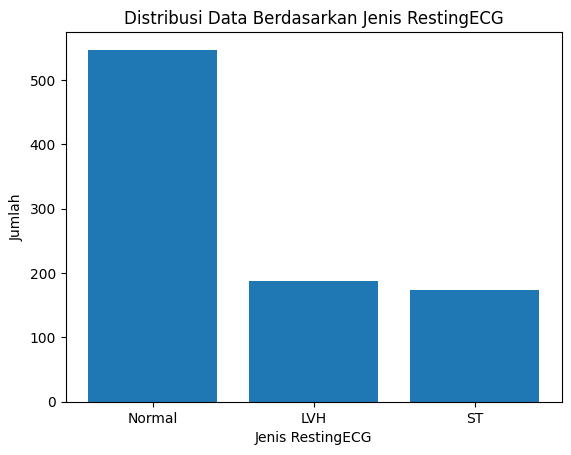

In [ ]:
# Menghitung jumlah data untuk setiap jenis RestingECG
resting_ecg_counts = dataset['RestingECG'].value_counts()

# Membuat bar chart
plt.bar(resting_ecg_counts.index, resting_ecg_counts.values)
plt.title('Distribusi Data Berdasarkan Jenis RestingECG')
plt.xlabel('Jenis RestingECG')
plt.ylabel('Jumlah')
plt.show()

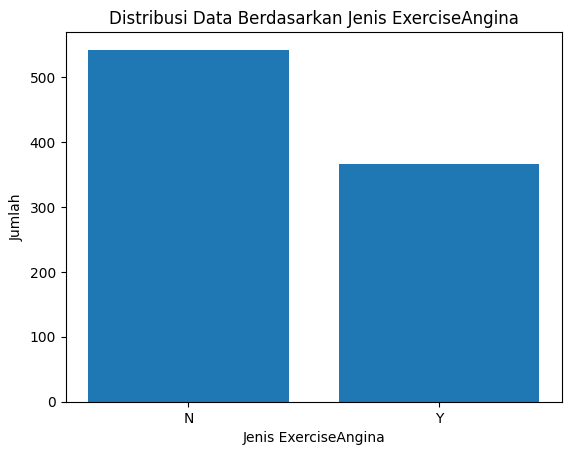

In [ ]:
# Menghitung jumlah data untuk setiap jenis ExerciseAngina
exercise_angina_counts = dataset['ExerciseAngina'].value_counts()

# Membuat bar chart
plt.bar(exercise_angina_counts.index, exercise_angina_counts.values)
plt.title('Distribusi Data Berdasarkan Jenis ExerciseAngina')
plt.xlabel('Jenis ExerciseAngina')
plt.ylabel('Jumlah')
plt.show()

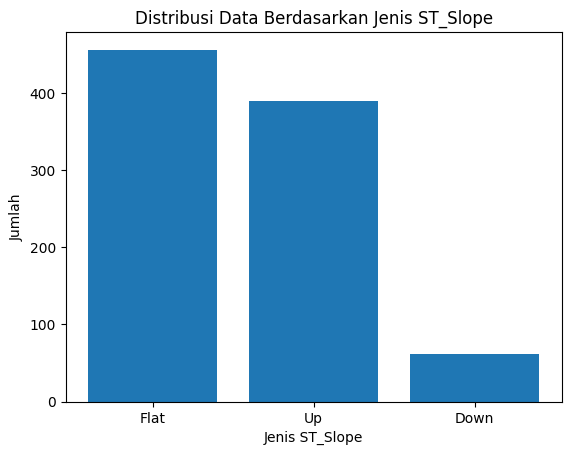

In [ ]:
# Menghitung jumlah data untuk setiap jenis ST_Slope
st_slope_counts = dataset['ST_Slope'].value_counts()

# Membuat bar chart
plt.bar(st_slope_counts.index, st_slope_counts.values)
plt.title('Distribusi Data Berdasarkan Jenis ST_Slope')
plt.xlabel('Jenis ST_Slope')
plt.ylabel('Jumlah')
plt.show()

Berdasarkan bar chart variabel ST_Slope:

Dominasi Kategori "Flat": Kategori "Flat" memiliki jumlah data terbanyak, menunjukkan bahwa sebagian besar individu dalam dataset memiliki ST_Slope yang datar.
Kategori "Up" Kedua Terbanyak: Kategori "Up" berada di urutan kedua dengan jumlah data yang cukup signifikan, meskipun lebih sedikit dari "Flat".
Kategori "Down" Paling Sedikit: Kategori "Down" memiliki jumlah data paling sedikit dibandingkan dengan kategori lainnya.
Secara umum, bar chart ini menunjukkan bahwa ST_Slope yang datar adalah yang paling umum dalam dataset ini, diikuti oleh ST_Slope yang naik, dan ST_Slope yang turun adalah yang paling jarang ditemukan. Informasi ini dapat menjadi penting dalam analisis lebih lanjut terkait dengan penyakit jantung.

**Menampilkan visualisasi variabel Non-Kategorikal (Age, RestingBP, Cholesterol, FastingBS, MaxHR, dan OledPeak)**

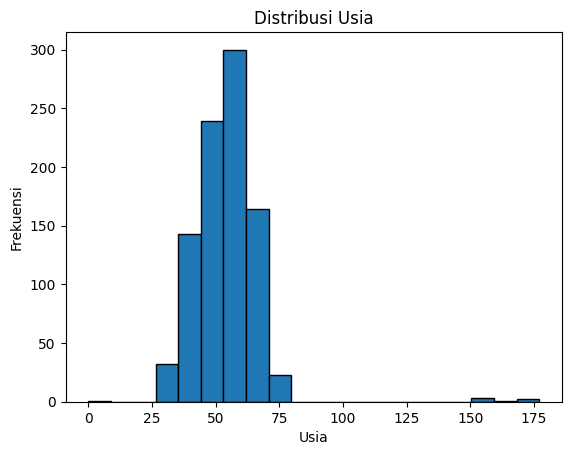

In [ ]:
# Membuat histogram untuk variabel Age
plt.hist(dataset['Age'].dropna(), bins=20, edgecolor='black')
plt.title('Distribusi Usia')
plt.xlabel('Usia')
plt.ylabel('Frekuensi')
plt.show()

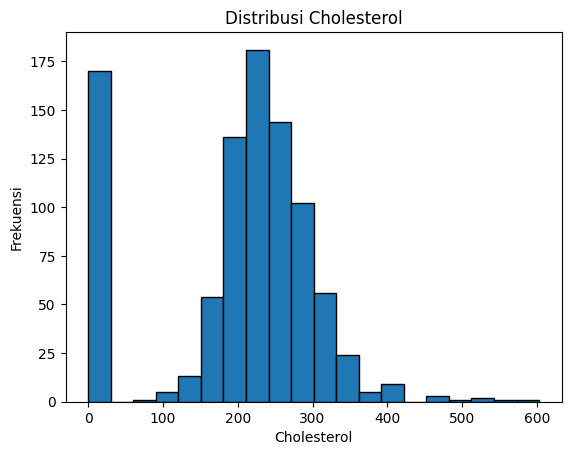

In [ ]:
# Membuat histogram untuk variabel Cholesterol
plt.hist(dataset['Cholesterol'], bins=20, edgecolor='black')
plt.title('Distribusi Cholesterol')
plt.xlabel('Cholesterol')
plt.ylabel('Frekuensi')
plt.show()

Berdasarkan histogram variabel Cholesterol:

Bentuk Distribusi: Distribusi kolesterol tampak sedikit miring ke kanan (positively skewed). Ini berarti ada beberapa individu dengan kadar kolesterol yang sangat tinggi, meskipun sebagian besar individu memiliki kadar kolesterol yang lebih rendah.
Pusat Distribusi: Sebagian besar data kolesterol tampaknya terpusat di sekitar nilai tertentu, meskipun ada penyebaran yang cukup luas. Anda dapat merujuk kembali ke statistik deskriptif (dataset.describe()) untuk mendapatkan nilai rata-rata (mean) atau median yang lebih tepat.
Penyebaran (Spread): Ada rentang nilai kolesterol yang cukup besar dalam dataset, dari nilai yang sangat rendah (mendekati 0) hingga nilai yang sangat tinggi (lebih dari 500).
Outlier: Ada kemungkinan adanya outlier atau nilai ekstrim pada sisi kanan distribusi, yaitu individu dengan kadar kolesterol yang sangat tinggi.
Secara umum, histogram ini menunjukkan bahwa sebagian besar individu dalam dataset memiliki kadar kolesterol dalam kisaran yang umum, tetapi ada juga sejumlah individu dengan kadar kolesterol yang tinggi yang mungkin perlu perhatian lebih lanjut.

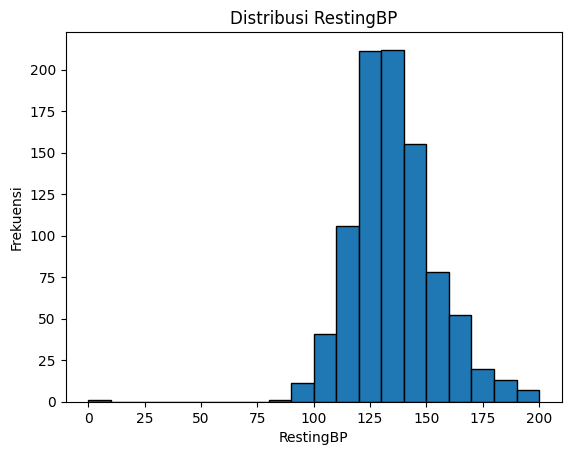

In [ ]:
# Membuat histogram untuk variabel RestingBP
plt.hist(dataset['RestingBP'], bins=20, edgecolor='black')
plt.title('Distribusi RestingBP')
plt.xlabel('RestingBP')
plt.ylabel('Frekuensi')
plt.show()

**Manampilkan Box Plot Diagram dari variabel Non-Kategorikal (Age, RestingBP, CHolesterol, fastingBS, MaxHR, OledPeak)**


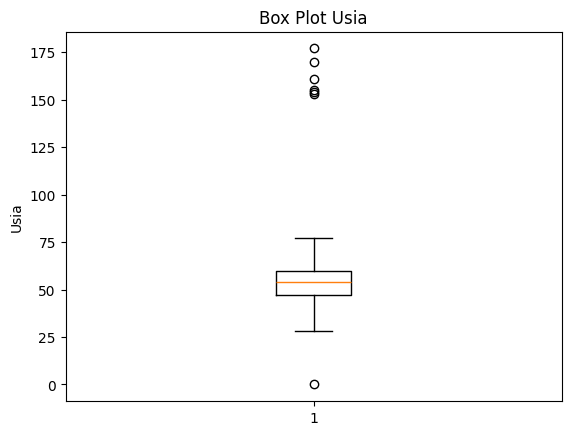

In [ ]:
# Membuat box plot untuk variabel Age
plt.boxplot(dataset['Age'].dropna())
plt.title('Box Plot Usia')
plt.ylabel('Usia')
plt.show()

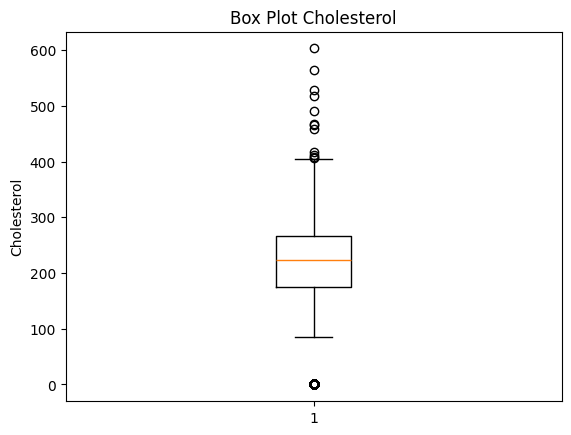

In [ ]:
# Membuat box plot untuk variabel Cholesterol
plt.boxplot(dataset['Cholesterol'])
plt.title('Box Plot Cholesterol')
plt.ylabel('Cholesterol')
plt.show()

**Membuat diagram Scatter Plot dari variabel Age dengan Cholesterol**

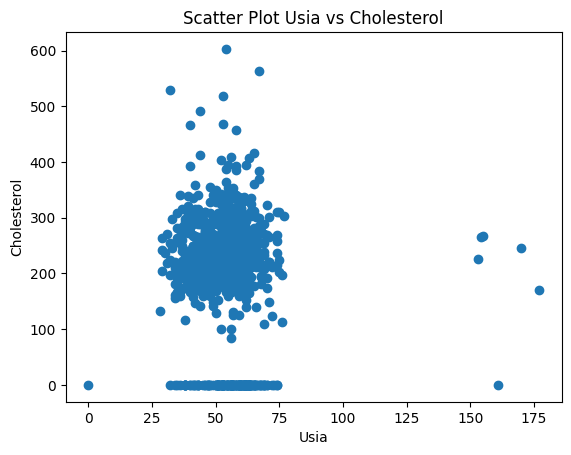

In [ ]:
# Membuat scatter plot untuk variabel Age dan Cholesterol
plt.scatter(dataset['Age'], dataset['Cholesterol'])
plt.title('Scatter Plot Usia vs Cholesterol')
plt.xlabel('Usia')
plt.ylabel('Cholesterol')
plt.show()

**Membuat diagram Scatter Plot dari pasangan variabel lain**

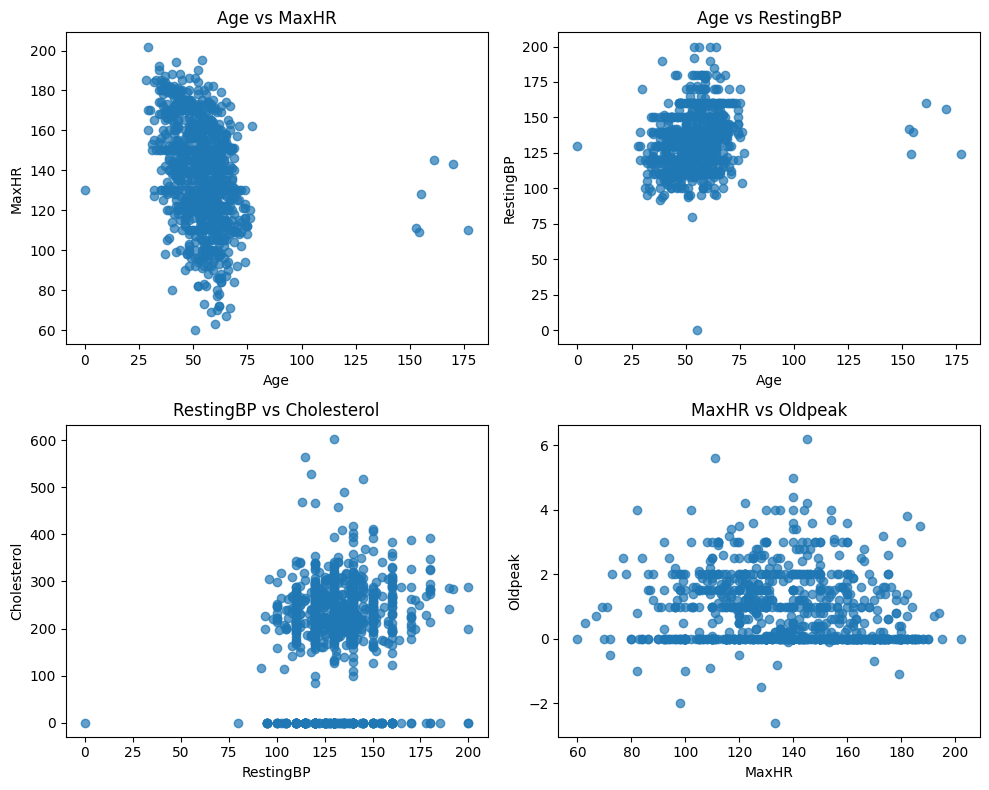

In [ ]:
# Membuat scatter plot untuk beberapa pasangan variabel numerik lainnya
scatter_pairs = [
    ('Age', 'MaxHR'),
    ('Age', 'RestingBP'),
    ('RestingBP', 'Cholesterol'),
    ('MaxHR', 'Oldpeak')
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (x_col, y_col) in zip(axes.ravel(), scatter_pairs):
    ax.scatter(dataset[x_col], dataset[y_col], alpha=0.7)
    ax.set_title(f'{x_col} vs {y_col}')
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

plt.tight_layout()
plt.show()


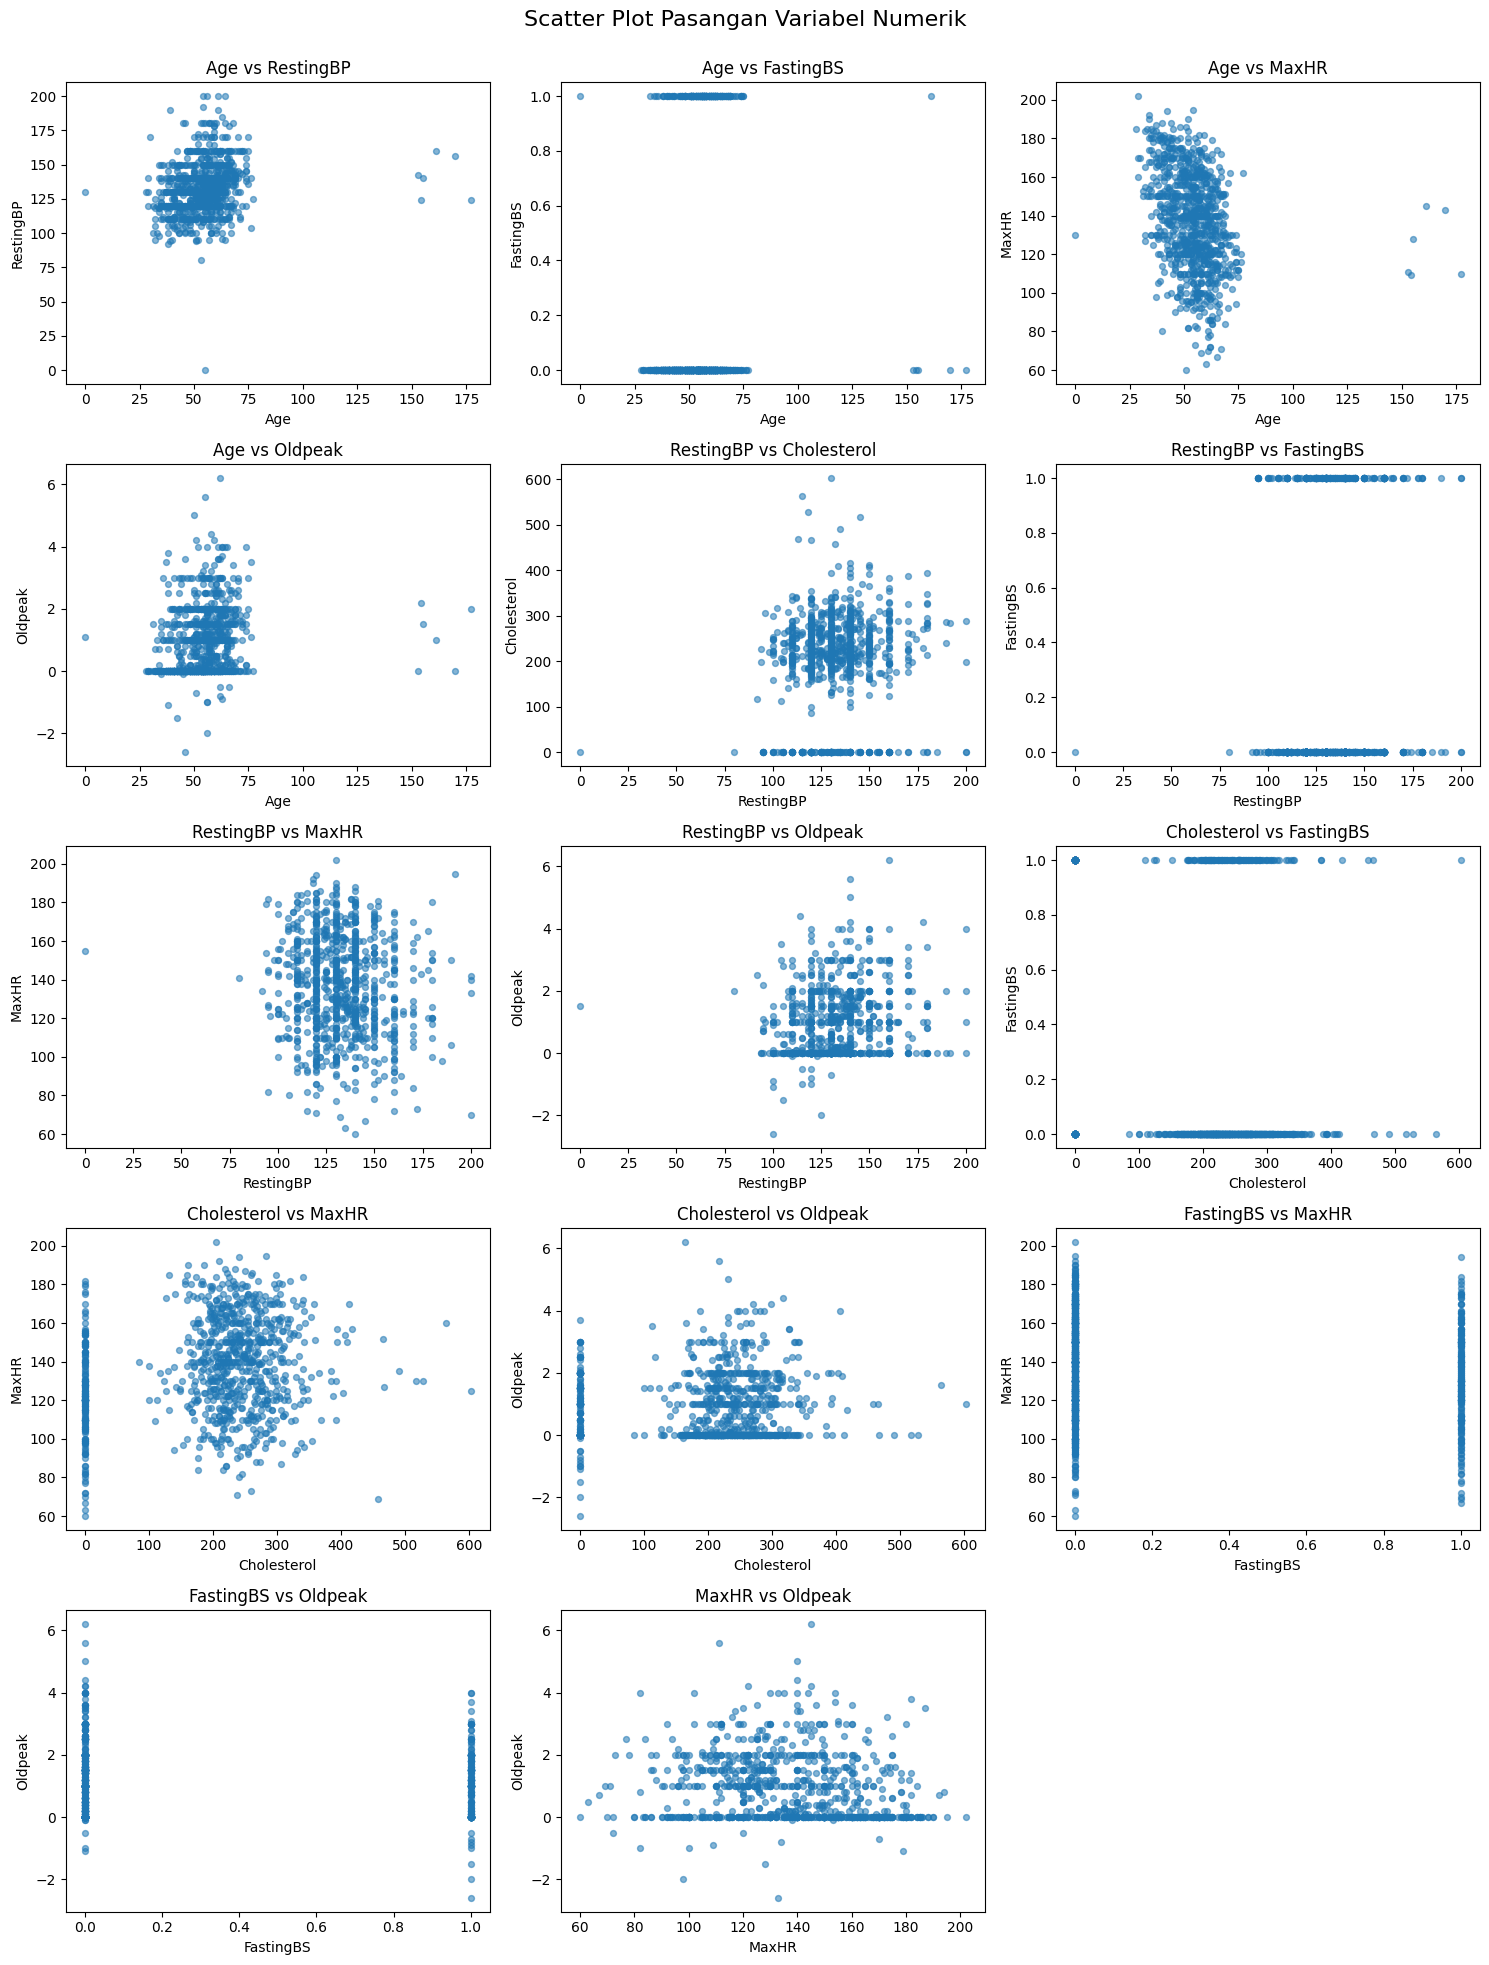

In [ ]:
# Menampilkan seluruh pasangan scatter plot yang belum dibuat dalam satu frame
from itertools import combinations

numeric_columns = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
existing_pair = frozenset(('Age', 'Cholesterol'))
scatter_pairs_lengkap = [
    (x_col, y_col)
    for x_col, y_col in combinations(numeric_columns, 2)
    if frozenset((x_col, y_col)) != existing_pair
]

fig, axes = plt.subplots(5, 3, figsize=(15, 20))
for ax, (x_col, y_col) in zip(axes.ravel(), scatter_pairs_lengkap):
    plot_data = dataset[[x_col, y_col]].dropna()
    ax.scatter(plot_data[x_col], plot_data[y_col], alpha=0.55, s=18)
    ax.set_title(f'{x_col} vs {y_col}')
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

for ax in axes.ravel()[len(scatter_pairs_lengkap):]:
    ax.set_visible(False)

fig.suptitle('Scatter Plot Pasangan Variabel Numerik', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


**Membuat diagram Pie Chart dari variabel Kategorikal (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope)**

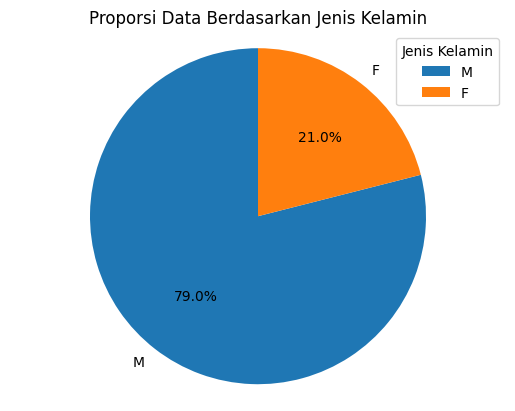

In [ ]:
# Menghitung jumlah data untuk setiap jenis kelamin
sex_counts = dataset['Sex'].value_counts()

# Membuat pie chart
plt.pie(sex_counts.values, labels=sex_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Proporsi Data Berdasarkan Jenis Kelamin')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.legend(title='Jenis Kelamin')
plt.show()

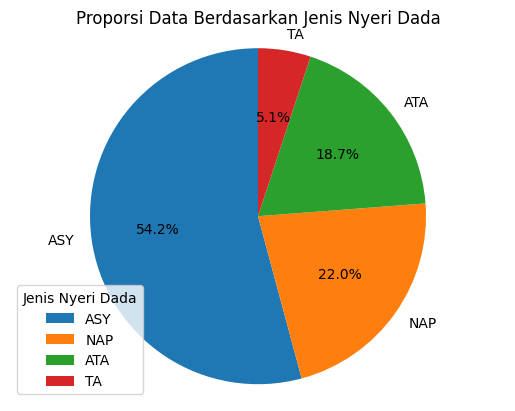

In [ ]:
# Menghitung jumlah data untuk setiap jenis ChestPainType
chest_pain_counts = dataset['ChestPainType'].value_counts()

# Membuat pie chart
plt.pie(chest_pain_counts.values, labels=chest_pain_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Proporsi Data Berdasarkan Jenis Nyeri Dada')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.legend(title='Jenis Nyeri Dada')
plt.show()

**Membuat diagram Pie Chart dari variabel Kategorikal lain**

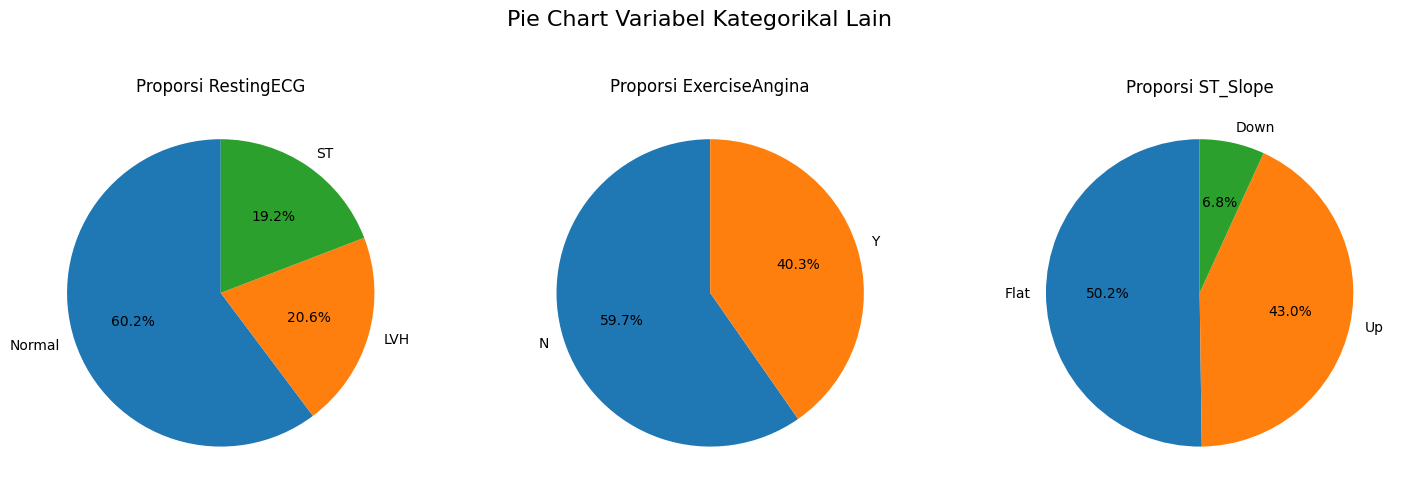

In [ ]:
# Menampilkan pie chart variabel kategorikal yang belum divisualisasikan dalam satu frame
pie_columns = ['RestingECG', 'ExerciseAngina', 'ST_Slope']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, column in zip(axes, pie_columns):
    counts = dataset[column].dropna().value_counts()
    ax.pie(
        counts.values,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=90
    )
    ax.set_title(f'Proporsi {column}')

fig.suptitle('Pie Chart Variabel Kategorikal Lain', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


**Korelasi antar variabel numerik**

In [ ]:
# Get numerical columns
numerical_cols = dataset.select_dtypes(include=np.number).columns

# Hitung matriks korelasi untuk variabel numerik
correlation_matrix = dataset[numerical_cols].corr(method='pearson')

# Tampilkan matriks korelasi
display(correlation_matrix)

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
Age,1.000000,0.212428,-0.060786,0.129330,-0.297505,0.195268,0.210551
RestingBP,0.212428,1.000000,0.102993,0.070175,-0.113664,0.167822,0.111221
Cholesterol,-0.060786,0.102993,1.000000,-0.261435,0.233410,0.050175,-0.234995
FastingBS,0.129330,0.070175,-0.261435,1.000000,-0.135099,0.056663,0.273380
MaxHR,-0.297505,-0.113664,0.233410,-0.135099,1.000000,-0.157414,-0.398814
Oldpeak,0.195268,0.167822,0.050175,0.056663,-0.157414,1.000000,0.398315
HeartDisease,0.210551,0.111221,-0.234995,0.273380,-0.398814,0.398315,1.000000


**Kesimpulan Korelasi Berdasarkan Koefisien Korelasi Pearson:**

Koefisien Korelasi Pearson mengukur kekuatan dan arah hubungan linier antara dua variabel numerik. Nilainya berkisar antara -1 hingga +1, di mana:
*   +1 menunjukkan korelasi positif sempurna
*   -1 menunjukkan korelasi negatif sempurna
*   0 menunjukkan tidak ada korelasi linier

Berdasarkan matriks korelasi:

*   **Korelasi dengan HeartDisease (Variabel Target):**
    *   `Oldpeak` memiliki korelasi positif moderat dengan `HeartDisease` (sekitar 0.40). Ini menunjukkan bahwa nilai Oldpeak yang lebih tinggi cenderung terkait dengan kemungkinan penyakit jantung yang lebih tinggi.
    *   `MaxHR` memiliki korelasi negatif moderat dengan `HeartDisease` (sekitar -0.40). Ini menunjukkan bahwa detak jantung maksimum yang lebih tinggi cenderung terkait dengan kemungkinan penyakit jantung yang lebih rendah.
    *   `FastingBS` memiliki korelasi positif lemah dengan `HeartDisease` (sekitar 0.27).
    *   `Age` memiliki korelasi positif lemah dengan `HeartDisease` (sekitar 0.21).
    *   `Cholesterol` memiliki korelasi negatif lemah dengan `HeartDisease` (sekitar -0.23).
    *   `RestingBP` memiliki korelasi positif sangat lemah dengan `HeartDisease` (sekitar 0.11).

*   **Korelasi Antar Variabel Prediktor Numerik:**
    *   Terdapat beberapa korelasi lemah hingga moderat antar variabel prediktor numerik (misalnya, Age dengan RestingBP sekitar 0.21, MaxHR dengan Cholesterol sekitar 0.24). Korelasi ini umumnya tidak terlalu tinggi, menunjukkan bahwa sebagian besar variabel prediktor numerik memberikan informasi yang relatif independen satu sama lain.

**Ringkasan:**

Analisis korelasi Pearson menunjukkan bahwa `Oldpeak` dan `MaxHR` memiliki korelasi yang paling kuat (meskipun moderat) dengan variabel target `HeartDisease`. Variabel numerik lainnya menunjukkan korelasi yang lebih lemah dengan `HeartDisease`. Korelasi antar variabel prediktor numerik umumnya rendah, yang merupakan hal baik karena menunjukkan sedikit multikolinearitas di antara fitur-fitur numerik. Informasi ini penting untuk pemilihan fitur dan pengembangan model prediksi penyakit jantung.

**Korelasi antara variabel Kategorikal dengan variabel Numerik**

In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Get categorical and numerical columns
categorical_cols = dataset.select_dtypes(include='object').columns
numerical_cols = dataset.select_dtypes(include=np.number).columns

# Perform ANOVA for each combination of categorical and numerical variables
anova_results = {}
for cat_col in categorical_cols:
    for num_col in numerical_cols:
        # Handle potential missing values in numerical column
        temp_df = dataset[[cat_col, num_col]].dropna()
        if len(temp_df) > 0:
            try:
                # Fit the ANOVA model
                model = ols(f'{num_col} ~ C({cat_col})', data=temp_df).fit()
                anova_table = sm.stats.anova_lm(model, typ=2)
                anova_results[f'{cat_col} vs {num_col}'] = anova_table['PR(>F)'][0]
            except Exception as e:
                anova_results[f'{cat_col} vs {num_col}'] = f'Error: {e}'
        else:
            anova_results[f'{cat_col} vs {num_col}'] = 'Not enough data after dropping NaNs'

# Display ANOVA results
print("ANOVA p-values:")
for key, value in anova_results.items():
    print(f"{key}: {value}")

/tmp/ipykernel_576/425706140.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  anova_results[f'{cat_col} vs {num_col}'] = anova_table['PR(>F)'][0]
/tmp/ipykernel_576/425706140.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  anova_results[f'{cat_col} vs {num_col}'] = anova_table['PR(>F)'][0]
/tmp/ipykernel_576/425706140.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  anova_results[f'{cat_col} vs {num_col}'] = anova_table

ANOVA p-values:
Sex vs Age: 0.056183931503381364
Sex vs RestingBP: 0.9198950772018136
Sex vs Cholesterol: 1.9462746161753133e-09
Sex vs FastingBS: 0.00017930049228338004
Sex vs MaxHR: 2.117942531048276e-08
Sex vs Oldpeak: 0.002090898727841574
Sex vs HeartDisease: 8.726552630323044e-21
ChestPainType vs Age: 4.798517615818942e-06
ChestPainType vs RestingBP: 0.10616346175510404
ChestPainType vs Cholesterol: 4.508636725192197e-05
ChestPainType vs FastingBS: 1.678333836464128e-05
ChestPainType vs MaxHR: 8.22633742394618e-28
ChestPainType vs Oldpeak: 6.227102433005481e-21
ChestPainType vs HeartDisease: 6.483433694066647e-68
RestingECG vs Age: 2.0416371445842197e-09
RestingECG vs RestingBP: 0.0014270700154176798
RestingECG vs Cholesterol: 1.4741610248620441e-08
RestingECG vs FastingBS: 0.0001771647701150444
RestingECG vs MaxHR: 3.6071462927858343e-07
RestingECG vs Oldpeak: 0.00127918909665408
RestingECG vs HeartDisease: 0.0032074010589912727
ExerciseAngina vs Age: 1.0950185015100617e-07
Exerc

/tmp/ipykernel_576/425706140.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  anova_results[f'{cat_col} vs {num_col}'] = anova_table['PR(>F)'][0]
/tmp/ipykernel_576/425706140.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  anova_results[f'{cat_col} vs {num_col}'] = anova_table['PR(>F)'][0]
/tmp/ipykernel_576/425706140.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  anova_results[f'{cat_col} vs {num_col}'] = anova_table

Korelasi antara variabel Kategorikal dengan variabel Numerik

**Kesimpulan Korelasi Berdasarkan ANOVA (dengan tingkat signifikansi α = 0.05):**

ANOVA digunakan untuk menguji apakah ada perbedaan yang signifikan dalam rata-rata variabel numerikal di antara grup-grup yang dibentuk oleh variabel kategorikal. Nilai p-value yang kecil (biasanya < 0.05) menunjukkan bahwa ada perbedaan rata-rata yang signifikan, yang mengindikasikan adanya hubungan atau korelasi antara variabel kategorikal dan variabel numerikal.

Berdasarkan hasil p-value ANOVA:

*   **Sex:**
    *   Memiliki korelasi signifikan dengan: Cholesterol (p < 0.05), FastingBS (p < 0.05), MaxHR (p < 0.05), Oldpeak (p < 0.05), dan HeartDisease (p < 0.05).
    *   Tidak memiliki korelasi signifikan dengan: Age (p > 0.05) dan RestingBP (p > 0.05).
*   **ChestPainType:**
    *   Memiliki korelasi signifikan dengan: Age (p < 0.05), Cholesterol (p < 0.05), FastingBS (p < 0.05), MaxHR (p < 0.05), Oldpeak (p < 0.05), dan HeartDisease (p < 0.05).
    *   Tidak memiliki korelasi signifikan dengan: RestingBP (p > 0.05).
*   **RestingECG:**
    *   Memiliki korelasi signifikan dengan: Age (p < 0.05), RestingBP (p < 0.05), Cholesterol (p < 0.05), FastingBS (p < 0.05), MaxHR (p < 0.05), Oldpeak (p < 0.05), dan HeartDisease (p < 0.05).
*   **ExerciseAngina:**
    *   Memiliki korelasi signifikan dengan: Age (p < 0.05), RestingBP (p < 0.05), MaxHR (p < 0.05), Oldpeak (p < 0.05), dan HeartDisease (p < 0.05).
    *   Tidak memiliki korelasi signifikan dengan: Cholesterol (p > 0.05) dan FastingBS (p > 0.05).
*   **ST_Slope:**
    *   Memiliki korelasi signifikan dengan: Age (p < 0.05), RestingBP (p < 0.05), Cholesterol (p < 0.05), FastingBS (p < 0.05), MaxHR (p < 0.05), Oldpeak (p < 0.05), dan HeartDisease (p < 0.05).

**Ringkasan:**

Sebagian besar variabel kategorikal menunjukkan korelasi yang signifikan dengan banyak variabel numerikal, termasuk variabel target HeartDisease. Ini menunjukkan bahwa kategori-kategori dalam variabel seperti Jenis Kelamin, Jenis Nyeri Dada, RestingECG, ExerciseAngina, dan ST_Slope memiliki pengaruh yang berbeda terhadap nilai rata-rata dari variabel numerikal terkait. Informasi ini penting untuk pemilihan fitur dalam membangun model prediksi penyakit jantung. Variabel kategorikal yang menunjukkan korelasi signifikan dengan HeartDisease (Sex, ChestPainType, RestingECG, ExerciseAngina, dan ST_Slope) kemungkinan besar merupakan prediktor yang baik untuk penyakit jantung.

**Korelasi antar variabel kategorikal**

In [ ]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):
    """ Calculate Cramer's V for two categorical variables. """
    contingency_table = pd.crosstab(x, y)
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    n = contingency_table.sum().sum()
    phi2 = chi2 / n
    # Correct for bias
    r, k = contingency_table.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Get categorical columns
categorical_cols = dataset.select_dtypes(include='object').columns

# Calculate Cramer's V matrix
cramers_v_matrix = pd.DataFrame(index=categorical_cols, columns=categorical_cols)

for col1 in categorical_cols:
    for col2 in categorical_cols:
        if col1 == col2:
            cramers_v_matrix.loc[col1, col2] = 1.0
        else:
            cramers_v_matrix.loc[col1, col2] = cramers_v(dataset[col1], dataset[col2])

# Display Cramer's V matrix
display(cramers_v_matrix)

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
Sex,1.0,0.18739,0.054682,0.187178,0.142984
ChestPainType,0.18739,1.0,0.090191,0.441525,0.287169
RestingECG,0.054682,0.090191,1.0,0.090739,0.046405
ExerciseAngina,0.187178,0.441525,0.090739,1.0,0.457643
ST_Slope,0.142984,0.287169,0.046405,0.457643,1.0


**Kesimpulan Korelasi Berdasarkan Cramer's V:**

Cramer's V adalah ukuran asosiasi antara dua variabel nominal. Nilainya berkisar antara 0 hingga 1, di mana:
*   0 menunjukkan tidak ada asosiasi
*   1 menunjukkan asosiasi sempurna

Interpretasi kekuatan asosiasi berdasarkan Cramer's V (umumnya):
*   0 hingga 0.10: Asosiasi dapat diabaikan atau sangat lemah
*   0.10 hingga 0.30: Asosiasi lemah
*   0.30 hingga 0.50: Asosiasi moderat
*   Di atas 0.50: Asosiasi kuat

Berdasarkan matriks Cramer's V:

*   Terdapat asosiasi moderat antara `ChestPainType` dan `ExerciseAngina` (sekitar 0.44).
*   Terdapat asosiasi moderat antara `ExerciseAngina` dan `ST_Slope` (sekitar 0.45).
*   Terdapat asosiasi lemah hingga dapat diabaikan antara pasangan variabel kategorikal lainnya (nilai Cramer's V sebagian besar di bawah 0.30).

**Ringkasan:**

Analisis Cramer's V menunjukkan bahwa ada asosiasi moderat antara `ChestPainType` dengan `ExerciseAngina`, dan antara `ExerciseAngina` dengan `ST_Slope`. Ini berarti bahwa kategori-kategori dalam pasangan variabel ini cenderung muncul bersamaan lebih sering daripada yang diperkirakan secara kebetulan. Asosiasi antara pasangan variabel kategorikal lainnya umumnya lemah. Informasi ini berguna untuk memahami hubungan antar fitur kategorikal dan dapat membantu dalam pemilihan fitur atau strategi *encoding* untuk model *machine learning*.

# **Validasi Data: mengidentifikasi sampel data yang tidak valid**

# **Pembersihan Data: menangani sampel data yang tidak valid**

**1. Mengidentifikasi variabel data yang memiliki nilai  kosong**

In [ ]:
# Menampilkan jumlah nilai kosong per variabel
print(dataset.isnull().sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


**2.  Mengganti nilai variabel Age yang kosong dengan nilai modus**

In [ ]:
# Mengganti nilai kosong pada kolom 'Age' dengan nilai mediannya
dataset['Age'].fillna(dataset['Age'].median(), inplace=True)

# Memverifikasi bahwa nilai kosong pada kolom 'Age' telah terisi
print("Jumlah nilai kosong pada kolom 'Age' setelah imputasi:", dataset['Age'].isnull().sum())

Jumlah nilai kosong pada kolom 'Age' setelah imputasi: 0


/tmp/ipykernel_576/3187352041.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Age'].fillna(dataset['Age'].median(), inplace=True)


**3.  Menghapus sampel yang memiliki variabel Sex yang kosong**

In [ ]:
# ============================================================
# MENGHAPUS SAMPEL DENGAN SEX KOSONG
# ============================================================
if 'Sex' in dataset.columns:
    jumlah_awal = len(dataset)
    dataset = dataset.dropna(subset=['Sex']).copy()
    jumlah_terhapus = jumlah_awal - len(dataset)

    print("Jumlah baris sebelum penghapusan:", jumlah_awal)
    print("Jumlah baris yang dihapus       :", jumlah_terhapus)
    print("Jumlah baris setelah penghapusan:", len(dataset))
    print("Sisa nilai kosong Sex           :", dataset['Sex'].isnull().sum())
else:
    print("Kolom Sex tidak ditemukan pada dataset.")


Jumlah baris sebelum penghapusan: 908
Jumlah baris yang dihapus       : 0
Jumlah baris setelah penghapusan: 908
Sisa nilai kosong Sex           : 0


**4. Mengidentifikasi variabel numerik yang memiliki nilai outlier**

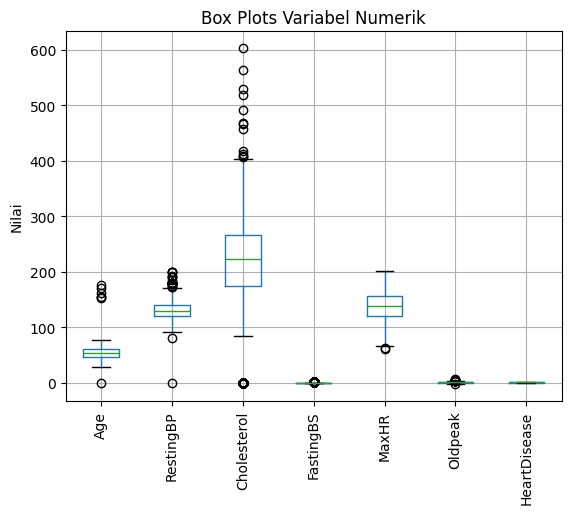

In [ ]:
# Mengidentifikasi variabel numerik
numerical_cols = dataset.select_dtypes(include=np.number).columns

# Membuat box plot untuk setiap variabel numerik dalam satu frame dengan label vertikal
dataset[numerical_cols].boxplot(rot=90)
plt.title('Box Plots Variabel Numerik')
plt.ylabel('Nilai')
plt.show()

** kecuali variabel FastingBS, OldPeak, dan HeartDisease**

In [ ]:
# ============================================================
# MENANGANI OUTLIER DENGAN METODE IQR
# ============================================================
# Variabel biner/target seperti FastingBS dan HeartDisease tidak diproses.
# Oldpeak juga dikecualikan sesuai instruksi latihan.

numerical_cols_to_handle = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']

outlier_handling_summary = []

for col in numerical_cols_to_handle:
    if col not in dataset.columns:
        continue

    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_before = ((dataset[col] < lower_bound) |
                      (dataset[col] > upper_bound)).sum()

    # Winsorization/Clipping:
    # nilai di bawah batas bawah menjadi lower_bound,
    # nilai di atas batas atas menjadi upper_bound.
    dataset[col] = dataset[col].clip(lower=lower_bound, upper=upper_bound)

    outlier_after = ((dataset[col] < lower_bound) |
                     (dataset[col] > upper_bound)).sum()

    outlier_handling_summary.append({
        'Variabel': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Sebelum': outlier_before,
        'Outlier Sesudah': outlier_after
    })

display(pd.DataFrame(outlier_handling_summary))


,Variabel,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Sebelum,Outlier Sesudah
0,Age,47.0,60.0,13.0,27.5,79.5,7,0
1,RestingBP,120.0,140.0,20.0,90.0,170.0,28,0
2,Cholesterol,175.0,267.0,92.0,37.0,405.0,182,0
3,MaxHR,120.0,156.0,36.0,66.0,210.0,2,0


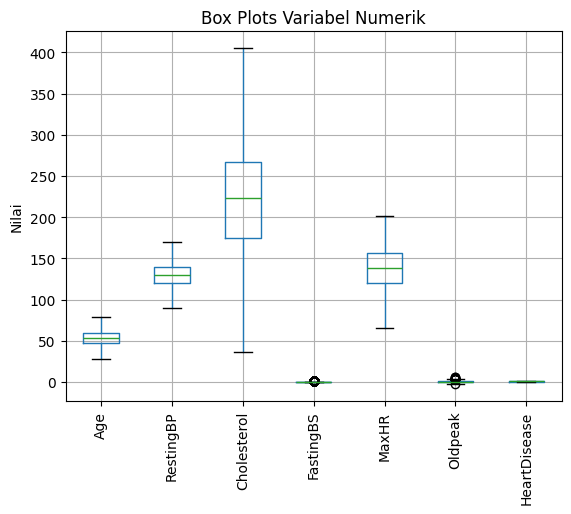

In [ ]:
# Mengidentifikasi variabel numerik
numerical_cols = dataset.select_dtypes(include=np.number).columns

# Membuat box plot untuk setiap variabel numerik dalam satu frame dengan label vertikal
dataset[numerical_cols].boxplot(rot=90)
plt.title('Box Plots Variabel Numerik')
plt.ylabel('Nilai')
plt.show()

# **Pemilihan Objek Data: pemilihan fitur data**

**1.  Mengkonversi variabel kategorikal menjadi numerik menggunakan Ordinal Encoder**

In [ ]:
# ============================================================
# ORDINAL ENCODING VARIABEL KATEGORIKAL
# ============================================================
from sklearn.preprocessing import OrdinalEncoder

categorical_cols = dataset.select_dtypes(include='object').columns.tolist()

if categorical_cols:
    ordinal_encoder = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    dataset[categorical_cols] = ordinal_encoder.fit_transform(
        dataset[categorical_cols]
    )

    print("Variabel kategorikal yang di-encode:")
    print(categorical_cols)

    # Menampilkan pemetaan kategori untuk membantu interpretasi.
    for col, categories in zip(categorical_cols, ordinal_encoder.categories_):
        mapping = {category: idx for idx, category in enumerate(categories)}
        print(f"{col}: {mapping}")
else:
    print("Tidak ada variabel bertipe object yang perlu di-encode.")

display(dataset.head())


Variabel kategorikal yang di-encode:
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Sex: {'F': 0, 'M': 1}
ChestPainType: {'ASY': 0, 'ATA': 1, 'NAP': 2, 'TA': 3}
RestingECG: {'LVH': 0, 'Normal': 1, 'ST': 2}
ExerciseAngina: {'N': 0, 'Y': 1}
ST_Slope: {'Down': 0, 'Flat': 1, 'Up': 2}


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,54.102086,1.0,1.0,140,289,0,1.0,172,0.0,0.0,2.0,0
1,49.000000,0.0,2.0,160,180,0,1.0,156,0.0,1.0,1.0,1
2,37.000000,1.0,1.0,130,283,0,2.0,98,0.0,0.0,2.0,0
3,48.000000,0.0,0.0,138,214,0,1.0,108,1.0,1.5,1.0,1
4,54.000000,1.0,2.0,150,195,0,1.0,122,0.0,0.0,2.0,0


In [ ]:
print(dataset.dtypes)

Age               float64
Sex               float64
ChestPainType     float64
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG        float64
MaxHR               int64
ExerciseAngina    float64
Oldpeak           float64
ST_Slope          float64
HeartDisease        int64
dtype: object


**2.  Menampilkan matriks korelasi antar variabel menggunakan Heatmap**

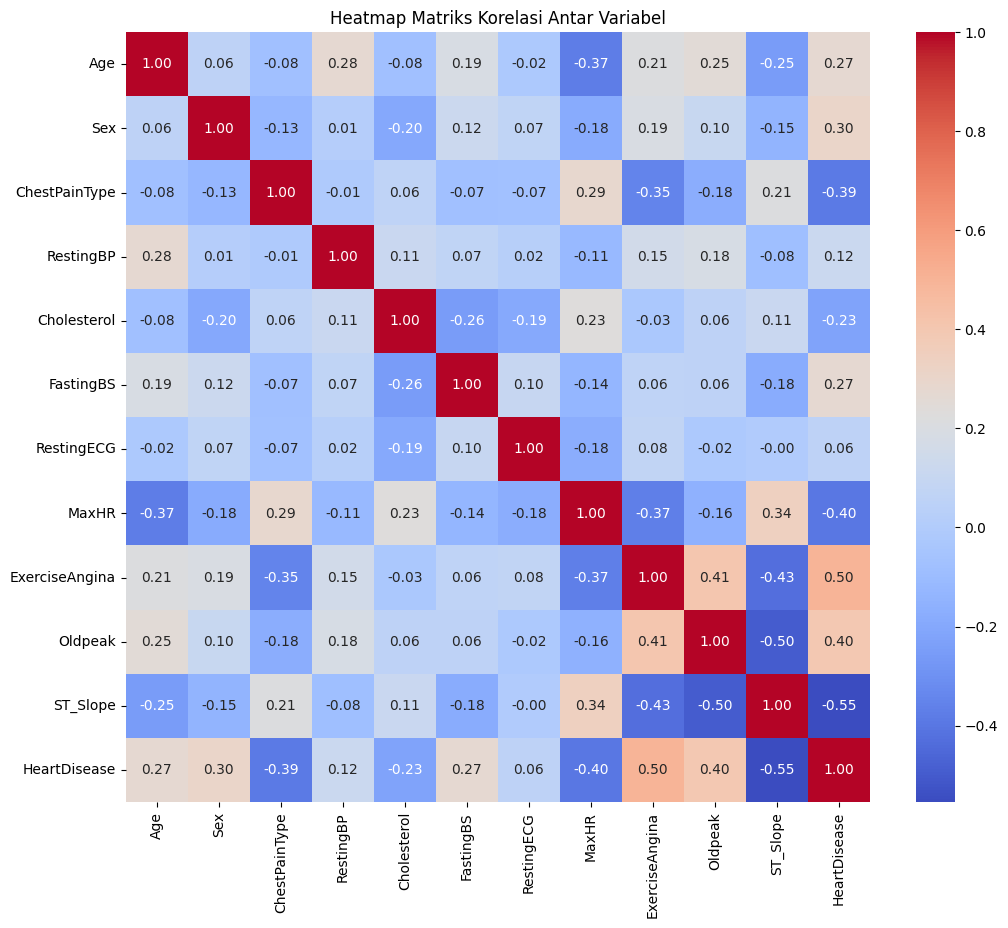

In [ ]:
import seaborn as sns

# Hitung matriks korelasi
correlation_matrix = dataset.corr()

# Buat heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Matriks Korelasi Antar Variabel')
plt.show()

In [ ]:
# Hitung matriks korelasi
correlation_matrix = dataset.corr()

# Urutkan variabel berdasarkan nilai absolut koefisien korelasi terhadap HeartDisease
correlation_with_heartdisease = correlation_matrix['HeartDisease'].abs().sort_values(ascending=False)

# Tampilkan hasil
print("Urutan variabel berdasarkan nilai absolut koefisien korelasi terhadap HeartDisease:")
print(correlation_with_heartdisease)

Urutan variabel berdasarkan nilai absolut koefisien korelasi terhadap HeartDisease:
HeartDisease      1.000000
ST_Slope          0.554575
ExerciseAngina    0.497976
MaxHR             0.398912
Oldpeak           0.398315
ChestPainType     0.387024
Sex               0.303381
FastingBS         0.273380
Age               0.273230
Cholesterol       0.225351
RestingBP         0.117202
RestingECG        0.056944
Name: HeartDisease, dtype: float64


**3. Menghitung Skor Feature Importance setiap variabel**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Pisahkan fitur (X) dan variabel target (y)
X = dataset.drop('HeartDisease', axis=1)
y = dataset['HeartDisease']

# Inisialisasi dan latih model Random Forest Classifier
model = RandomForestClassifier(random_state=42)
model.fit(X, y)

# Dapatkan skor Feature Importance
feature_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

# Tampilkan skor Feature Importance
print("Skor Feature Importance terhadap HeartDisease:")
print(feature_importances)

Skor Feature Importance terhadap HeartDisease:
ST_Slope          0.232898
ChestPainType     0.120745
Cholesterol       0.112238
Oldpeak           0.109608
MaxHR             0.107639
ExerciseAngina    0.080951
Age               0.077730
RestingBP         0.071412
Sex               0.034645
RestingECG        0.028127
FastingBS         0.024006
dtype: float64


**4. Menghitung Skor SHAP setiap variabel**

In [ ]:
# Menyiapkan data fitur dan label untuk analisis SHAP
X_shap = X.copy()
y_shap = y.copy()

print('Data SHAP siap digunakan.')
print('Bentuk X_shap:', X_shap.shape)
print('Bentuk y_shap:', y_shap.shape)


Data SHAP siap digunakan.
Bentuk X_shap: (908, 11)
Bentuk y_shap: (908,)


In [ ]:
import xgboost as xgb

# Inisialisasi dan latih model XGBoost Classifier
xgb_model = xgb.XGBClassifier(random_state=42)
xgb_model.fit(X, y)

print("Model XGBoost telah dilatih.")

Model XGBoost telah dilatih.


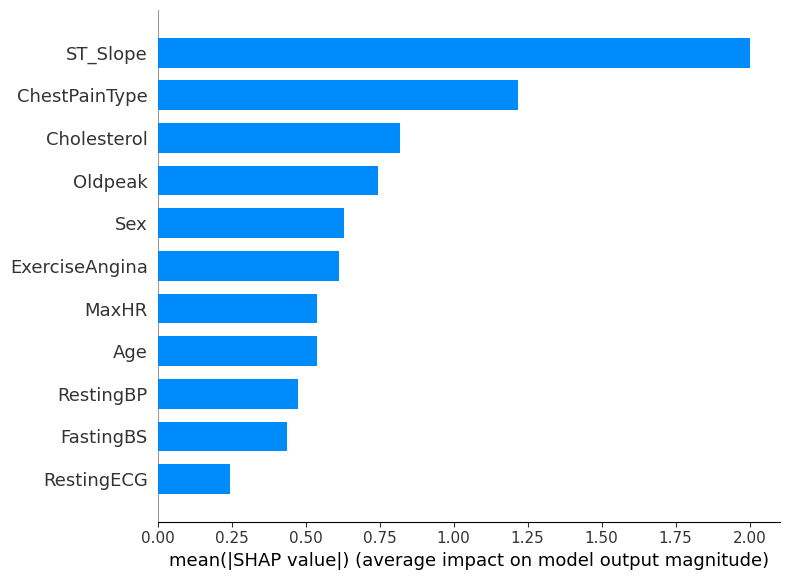

In [ ]:
import shap

# Inisialisasi SHAP explainer untuk model XGBoost
explainer_xgb = shap.TreeExplainer(xgb_model)

# Hitung nilai SHAP untuk data menggunakan model XGBoost
shap_values_xgb = explainer_xgb.shap_values(X)

# Ringkasan plot SHAP untuk model XGBoost
shap.summary_plot(shap_values_xgb, X, plot_type="bar")

# Penceritaan Data dari Hasil Skor SHAP (Model XGBoost)

Hasil analisis SHAP pada model XGBoost memberikan wawasan mendalam tentang bagaimana setiap fitur memengaruhi prediksi model terkait kemungkinan penyakit jantung. Berdasarkan plot ringkasan SHAP:

1.  **ST_Slope (Kemiringan Segmen ST):** Fitur ini muncul sebagai prediktor paling penting. Titik-titik pada plot menunjukkan bahwa nilai `ST_Slope` yang tinggi (cenderung "Up" atau 2.0 setelah *encoding*) secara signifikan menurunkan nilai SHAP, yang berarti menurunkan kemungkinan prediksi penyakit jantung. Sebaliknya, nilai `ST_Slope` yang rendah (cenderung "Flat" atau 1.0 setelah *encoding*) memiliki nilai SHAP yang tinggi, yang berarti meningkatkan kemungkinan prediksi penyakit jantung. Ini konsisten dengan pemahaman medis bahwa ST *depression* (segmen ST mendatar atau turun) saat berolahraga seringkali merupakan indikator iskemia miokard.

2.  **ChestPainType (Jenis Nyeri Dada):** Fitur ini juga sangat penting. Plot SHAP menunjukkan bahwa jenis nyeri dada tertentu (kemungkinan "ASY" atau 0.0 setelah *encoding*) memiliki nilai SHAP yang tinggi, meningkatkan kemungkinan prediksi penyakit jantung. Sementara itu, jenis nyeri dada lainnya (seperti "ATA" atau 1.0 setelah *encoding*) memiliki nilai SHAP yang lebih rendah atau negatif, menurunkan kemungkinan prediksi penyakit jantung. Ini menyoroti pentingnya membedakan jenis nyeri dada dalam mendiagnosis penyakit jantung.

3.  **Oldpeak:** Fitur ini adalah prediktor penting ketiga. Nilai `Oldpeak` yang tinggi (menunjukkan depresi ST yang lebih besar) memiliki nilai SHAP yang tinggi, secara signifikan meningkatkan kemungkinan prediksi penyakit jantung. Sebaliknya, nilai `Oldpeak` yang rendah memiliki nilai SHAP yang rendah atau negatif, menurunkan kemungkinan prediksi penyakit jantung. Ini sejalan dengan peran `Oldpeak` sebagai indikator tingkat keparahan iskemia saat berolahraga.

Fitur-fitur lain seperti `MaxHR` (Detak Jantung Maksimum), `Cholesterol`, dan `ExerciseAngina` juga memiliki pengaruh yang cukup besar, meskipun sedikit di bawah tiga fitur teratas. Misalnya, `MaxHR` yang tinggi cenderung menurunkan kemungkinan prediksi penyakit jantung, sementara `ExerciseAngina` yang ada (nilai 1.0 setelah *encoding*) cenderung meningkatkan kemungkinan prediksi penyakit jantung.

Secara keseluruhan, analisis SHAP mengkonfirmasi bahwa fitur-fitur klinis kunci seperti `ST_Slope`, `ChestPainType`, dan `Oldpeak` adalah prediktor yang sangat kuat untuk penyakit jantung dalam dataset ini menurut model XGBoost. Memahami bagaimana nilai-nilai spesifik dari fitur-fitur ini memengaruhi prediksi model memberikan transparansi dan kepercayaan pada hasil model.

# **Mengkonstruksi (Mentransformasi Fitur) Data**

**1.  Normalisasi Fitur Data**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Normalisasi Fitur ke rentang 0 sampai 1
minmax_scaler = MinMaxScaler()
X_normalized = pd.DataFrame(
    minmax_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

display(X_normalized.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,0.511579,1.0,0.333333,0.625,0.684783,0.0,0.5,0.779412,0.0,0.295455,1.0
1,0.413462,0.0,0.666667,0.875,0.388587,0.0,0.5,0.661765,0.0,0.409091,0.5
2,0.182692,1.0,0.333333,0.500,0.668478,0.0,1.0,0.235294,0.0,0.295455,1.0
3,0.394231,0.0,0.000000,0.600,0.480978,0.0,0.5,0.308824,1.0,0.465909,0.5
4,0.509615,1.0,0.666667,0.750,0.429348,0.0,0.5,0.411765,0.0,0.295455,1.0


**2.  Standardisasi Fitur Data**

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardisasi Fitur
standard_scaler = StandardScaler()
X_standardized = pd.DataFrame(
    standard_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

display(X_standardized.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,0.051874,0.516128,0.230112,0.462987,0.889997,-0.550205,0.022712,1.382876,-0.821752,-0.830999,1.053967
1,-0.476785,-1.937505,1.274820,1.638579,-0.265031,-0.550205,0.022712,0.753969,-0.821752,0.106094,-0.596037
2,-1.720181,0.516128,0.230112,-0.124810,0.826417,-0.550205,1.609071,-1.525817,-0.821752,-0.830999,1.053967
3,-0.580401,-1.937505,-0.814596,0.345427,0.095253,-0.550205,0.022712,-1.132751,1.216912,0.574640,-0.596037
4,0.041297,0.516128,1.274820,1.050783,-0.106083,-0.550205,0.022712,-0.582457,-0.821752,-0.830999,1.053967


**3. Binning**

In [ ]:
# Membagi variabel Age ke beberapa kelompok umur
age_bins = [0, 40, 50, 60, np.inf]
age_labels = ['<=40', '41-50', '51-60', '>60']

dataset_binning = dataset.copy()
dataset_binning['Age_Bin'] = pd.cut(
    dataset_binning['Age'],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

display(dataset_binning[['Age', 'Age_Bin', 'HeartDisease']].head())
print(dataset_binning['Age_Bin'].value_counts().sort_index())


,Age,Age_Bin,HeartDisease
0,54.102086,51-60,0
1,49.000000,41-50,1
2,37.000000,<=40,0
3,48.000000,41-50,1
4,54.000000,51-60,0


Age_Bin
<=40      92
41-50    221
51-60    373
>60      222
Name: count, dtype: int64


**4.  Principal Component Analysis (PCA)**

Explained variance ratio: [0.25001468 0.13419107]


,PC1,PC2,HeartDisease
0,-1.760963,0.393471,0
1,-1.082665,1.130438,1
2,-1.095531,-1.144725,0
3,1.006595,1.045556,1
4,-1.017408,-0.335407,0


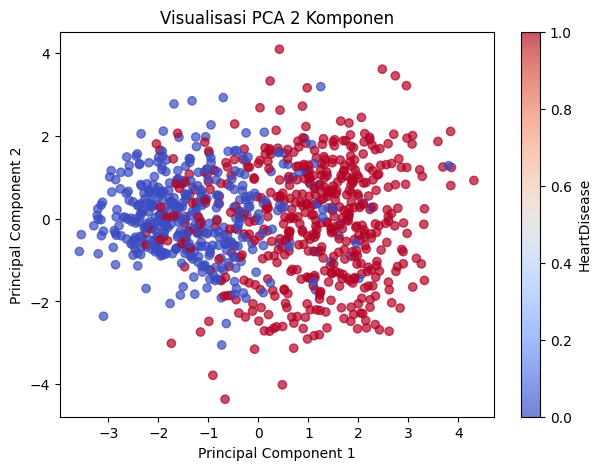

In [ ]:
from sklearn.decomposition import PCA

# Mereduksi fitur menjadi 2 komponen utama untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=X.index)
pca_df['HeartDisease'] = y.values

print('Explained variance ratio:', pca.explained_variance_ratio_)
display(pca_df.head())

plt.figure(figsize=(7, 5))
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=pca_df['HeartDisease'], cmap='coolwarm', alpha=0.7)
plt.title('Visualisasi PCA 2 Komponen')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='HeartDisease')
plt.show()


# **Penentuan Label Data**

,Jumlah
HeartDisease,
0,405
1,503


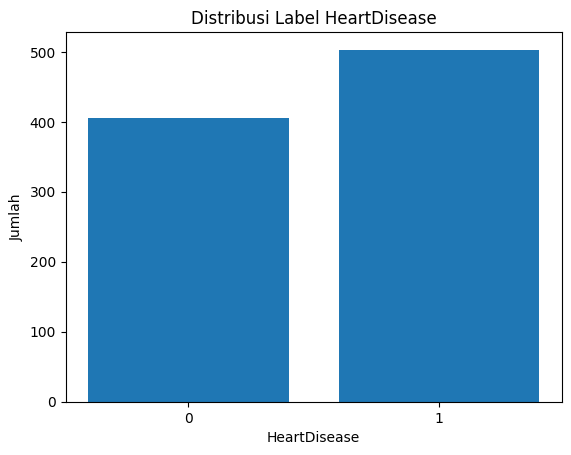

In [ ]:
# Menentukan kolom label dan melihat distribusi kelas target
target_column = 'HeartDisease'
label_counts = dataset[target_column].value_counts().sort_index()

display(label_counts.rename('Jumlah').to_frame())

plt.bar(label_counts.index.astype(str), label_counts.values)
plt.title('Distribusi Label HeartDisease')
plt.xlabel('HeartDisease')
plt.ylabel('Jumlah')
plt.show()


# **Pemodelan Data**

**1. Membuat Salinan Data**

In [ ]:
OldDataset = dataset

**2. Membagi dataset menjadi matriks data dan vektor target**


In [ ]:
# Memilih variabel fitur (X) dan variabel target (y) berdasarkan analisis sebelumnya
X = dataset[['ST_Slope', 'ChestPainType', 'Oldpeak', 'Cholesterol', 'Sex']]
y = dataset['HeartDisease']

print("Variabel fitur (X) dan variabel target (y) telah dibagi.")
print("Bentuk matriks X:", X.shape)
print("Bentuk vektor y:", y.shape)

Variabel fitur (X) dan variabel target (y) telah dibagi.
Bentuk matriks X: (908, 5)
Bentuk vektor y: (908,)


**3. Hold-out Cross Validation**

In [ ]:
# ============================================================
# HOLD-OUT CROSS VALIDATION
# ============================================================
from sklearn.model_selection import train_test_split

# stratify=y menjaga proporsi kelas HeartDisease pada train dan test.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Pembagian data selesai.")
print(f"X_train: {X_train.shape}")
print(f"X_test : {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test : {y_test.shape}")

print("\nProporsi label data training:")
display(y_train.value_counts(normalize=True).sort_index().rename("Proporsi").to_frame())

print("Proporsi label data testing:")
display(y_test.value_counts(normalize=True).sort_index().rename("Proporsi").to_frame())


Pembagian data selesai.
X_train: (726, 5)
X_test : (182, 5)
y_train: (726,)
y_test : (182,)

Proporsi label data training:


,Proporsi
HeartDisease,
0,0.446281
1,0.553719


Proporsi label data testing:


,Proporsi
HeartDisease,
0,0.445055
1,0.554945


# **Pemodelan Decision Tree**

**1.  Training Model Decision Tree (max depth = 3)**

Prompt: Training model Decision Tree dengan maximum depth = 3. Training Model Decsion Tree menggunakan X_train dan y_train. Testing Model Decision Tree menggunakan X_test dan y_test. Metriks kinerja model: accuracy, precision, recall, F1 score, dan AUC ROC. Tampilkan kurva ROC.

Metrik Kinerja Model Decision Tree (max_depth=3):
Accuracy: 0.8242
Precision: 0.8224
Recall: 0.8713
F1 Score: 0.8462
AUC-ROC: 0.8690

Classification Report (max_depth=3):
              precision    recall  f1-score   support

           0       0.83      0.77      0.79        81
           1       0.82      0.87      0.85       101

    accuracy                           0.82       182
   macro avg       0.82      0.82      0.82       182
weighted avg       0.82      0.82      0.82       182



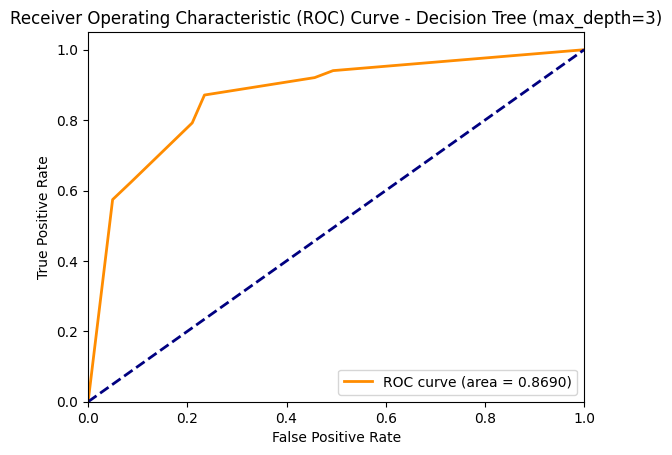

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt

# Inisialisasi model Decision Tree dengan max_depth = 3
model_dt_pruned = DecisionTreeClassifier(max_depth=3, random_state=42)

# Latih model menggunakan data training
model_dt_pruned.fit(X_train, y_train)

# Lakukan prediksi pada data testing
y_pred_dt_pruned = model_dt_pruned.predict(X_test)

# Hitung metrik kinerja klasifikasi
accuracy_dt_pruned = accuracy_score(y_test, y_pred_dt_pruned)
precision_dt_pruned = precision_score(y_test, y_pred_dt_pruned)
recall_dt_pruned = recall_score(y_test, y_pred_dt_pruned)
f1_dt_pruned = f1_score(y_test, y_pred_dt_pruned)
fpr_dt_pruned, tpr_dt_pruned, thresholds_dt_pruned = roc_curve(y_test, model_dt_pruned.predict_proba(X_test)[:, 1])
auc_dt_pruned = auc(fpr_dt_pruned, tpr_dt_pruned)

# Tampilkan metrik kinerja
print("Metrik Kinerja Model Decision Tree (max_depth=3):")
print(f"Accuracy: {accuracy_dt_pruned:.4f}")
print(f"Precision: {precision_dt_pruned:.4f}")
print(f"Recall: {recall_dt_pruned:.4f}")
print(f"F1 Score: {f1_dt_pruned:.4f}")
print(f"AUC-ROC: {auc_dt_pruned:.4f}")

# Tampilkan classification report
print("\nClassification Report (max_depth=3):")
print(classification_report(y_test, y_pred_dt_pruned))

# Gambarkan kurva ROC
plt.figure()
plt.plot(fpr_dt_pruned, tpr_dt_pruned, color='darkorange', lw=2, label=f'ROC curve (area = {auc_dt_pruned:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Decision Tree (max_depth=3)')
plt.legend(loc="lower right")
plt.show()

**Menampilkan model decision tree hasil training**

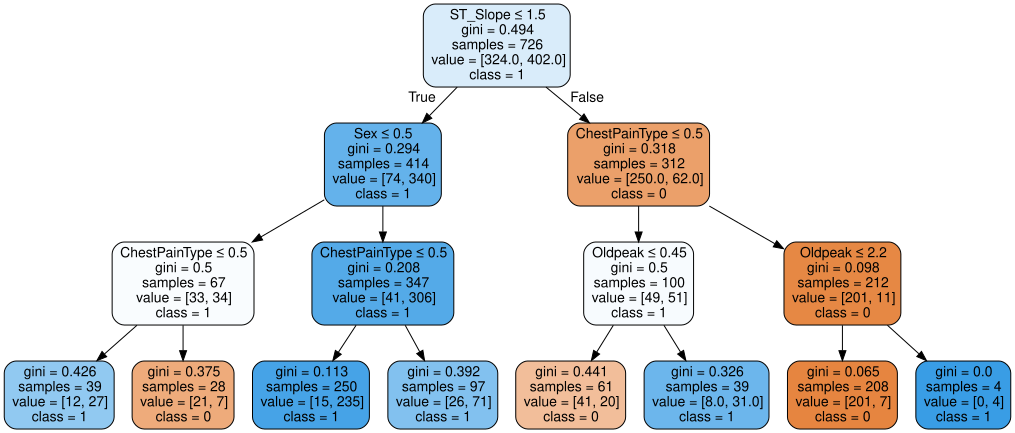

In [ ]:
from sklearn.tree import export_graphviz
import graphviz

dot_data = export_graphviz(model_dt_pruned,
     out_file=None,
     feature_names=X.columns,
     class_names=['0','1'],
     filled=True, rounded=True,
     special_characters=True)
graph = graphviz.Source(dot_data)
display(graph)

Confusion Matrix:
[[68 13]
 [19 82]]


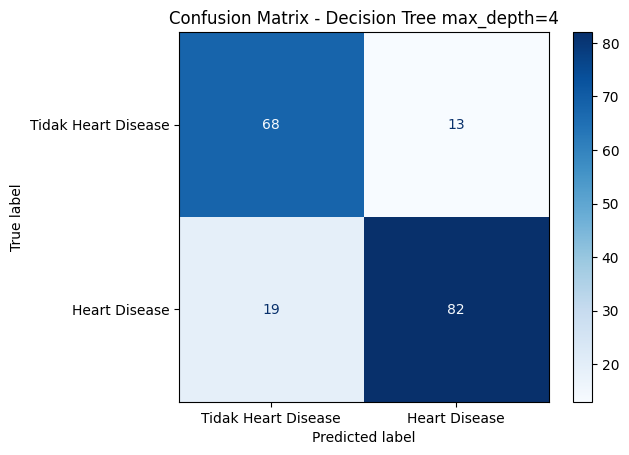

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred_dt_pruned)

print("Confusion Matrix:")
print(cm)

# Visualisasi confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Tidak Heart Disease', 'Heart Disease']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Decision Tree max_depth=4')
plt.show()

**2. Training Model Decision Tree (max depth = 4)**

Metrik Kinerja Model Decision Tree (max_depth=4):
Accuracy: 0.8407
Precision: 0.8273
Recall: 0.9010
F1 Score: 0.8626
AUC-ROC: 0.8777

Classification Report (max_depth=4):
              precision    recall  f1-score   support

           0       0.86      0.77      0.81        81
           1       0.83      0.90      0.86       101

    accuracy                           0.84       182
   macro avg       0.84      0.83      0.84       182
weighted avg       0.84      0.84      0.84       182



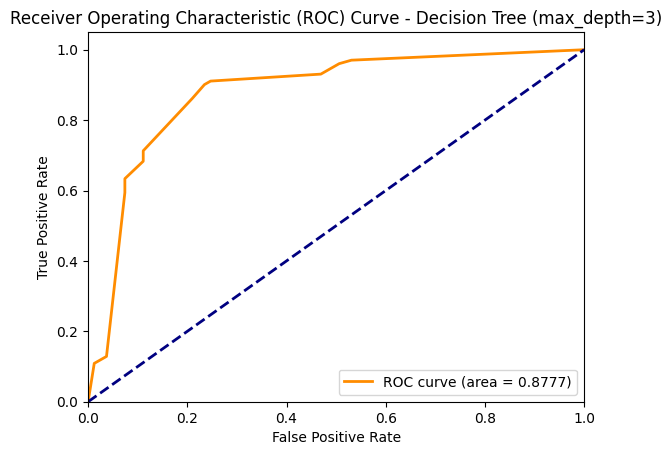

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt

# Inisialisasi model Decision Tree dengan max_depth = 4
model_dt_pruned = DecisionTreeClassifier(max_depth=4, random_state=42)

# Latih model menggunakan data training
model_dt_pruned.fit(X_train, y_train)

# Lakukan prediksi pada data testing
y_pred_dt_pruned = model_dt_pruned.predict(X_test)

# Hitung metrik kinerja klasifikasi
accuracy_dt_pruned = accuracy_score(y_test, y_pred_dt_pruned)
precision_dt_pruned = precision_score(y_test, y_pred_dt_pruned)
recall_dt_pruned = recall_score(y_test, y_pred_dt_pruned)
f1_dt_pruned = f1_score(y_test, y_pred_dt_pruned)
fpr_dt_pruned, tpr_dt_pruned, thresholds_dt_pruned = roc_curve(y_test, model_dt_pruned.predict_proba(X_test)[:, 1])
auc_dt_pruned = auc(fpr_dt_pruned, tpr_dt_pruned)

# Tampilkan metrik kinerja
print("Metrik Kinerja Model Decision Tree (max_depth=4):")
print(f"Accuracy: {accuracy_dt_pruned:.4f}")
print(f"Precision: {precision_dt_pruned:.4f}")
print(f"Recall: {recall_dt_pruned:.4f}")
print(f"F1 Score: {f1_dt_pruned:.4f}")
print(f"AUC-ROC: {auc_dt_pruned:.4f}")

# Tampilkan classification report
print("\nClassification Report (max_depth=4):")
print(classification_report(y_test, y_pred_dt_pruned))

# Gambarkan kurva ROC
plt.figure()
plt.plot(fpr_dt_pruned, tpr_dt_pruned, color='darkorange', lw=2, label=f'ROC curve (area = {auc_dt_pruned:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Decision Tree (max_depth=3)')
plt.legend(loc="lower right")
plt.show()

**Menampilkan model decision tree hasil training**

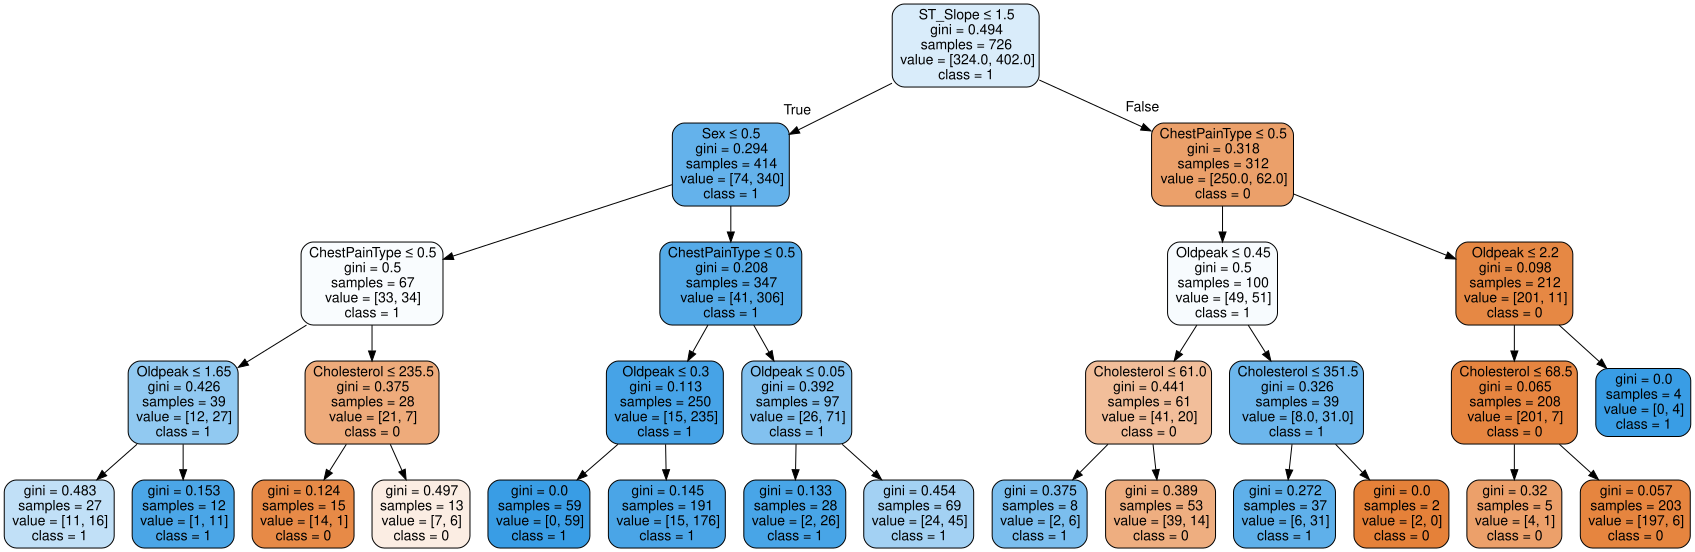

In [ ]:
from sklearn.tree import export_graphviz
import graphviz

dot_data = export_graphviz(model_dt_pruned,
     out_file=None,
     feature_names=X.columns,
     class_names=['0','1'],
     filled=True, rounded=True,
     special_characters=True)
graph = graphviz.Source(dot_data)
display(graph)

**3. Training Model Decision Tree (max depth = 5)**

Metrik Kinerja Model Decision Tree (max_depth=3):
Accuracy: 0.8242
Precision: 0.8632
Recall: 0.8119
F1 Score: 0.8367
AUC-ROC: 0.8653

Classification Report (max_depth=3):
              precision    recall  f1-score   support

           0       0.78      0.84      0.81        81
           1       0.86      0.81      0.84       101

    accuracy                           0.82       182
   macro avg       0.82      0.83      0.82       182
weighted avg       0.83      0.82      0.82       182



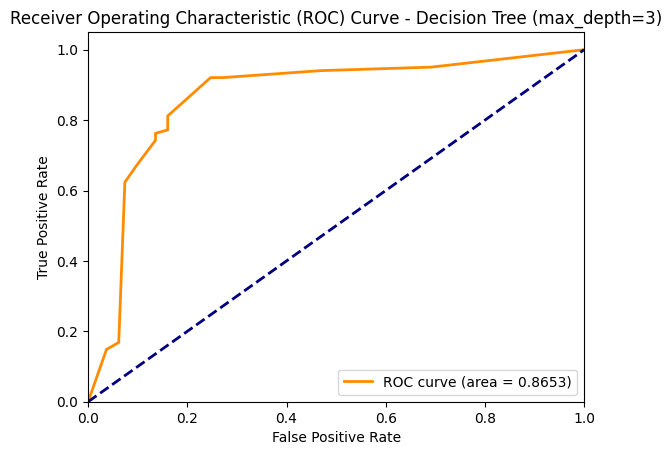

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt

# Inisialisasi model Decision Tree dengan max_depth = 5
model_dt_pruned = DecisionTreeClassifier(max_depth=5, random_state=42)

# Latih model menggunakan data training
model_dt_pruned.fit(X_train, y_train)

# Lakukan prediksi pada data testing
y_pred_dt_pruned = model_dt_pruned.predict(X_test)

# Hitung metrik kinerja klasifikasi
accuracy_dt_pruned = accuracy_score(y_test, y_pred_dt_pruned)
precision_dt_pruned = precision_score(y_test, y_pred_dt_pruned)
recall_dt_pruned = recall_score(y_test, y_pred_dt_pruned)
f1_dt_pruned = f1_score(y_test, y_pred_dt_pruned)
fpr_dt_pruned, tpr_dt_pruned, thresholds_dt_pruned = roc_curve(y_test, model_dt_pruned.predict_proba(X_test)[:, 1])
auc_dt_pruned = auc(fpr_dt_pruned, tpr_dt_pruned)

# Tampilkan metrik kinerja
print("Metrik Kinerja Model Decision Tree (max_depth=3):")
print(f"Accuracy: {accuracy_dt_pruned:.4f}")
print(f"Precision: {precision_dt_pruned:.4f}")
print(f"Recall: {recall_dt_pruned:.4f}")
print(f"F1 Score: {f1_dt_pruned:.4f}")
print(f"AUC-ROC: {auc_dt_pruned:.4f}")

# Tampilkan classification report
print("\nClassification Report (max_depth=3):")
print(classification_report(y_test, y_pred_dt_pruned))

# Gambarkan kurva ROC
plt.figure()
plt.plot(fpr_dt_pruned, tpr_dt_pruned, color='darkorange', lw=2, label=f'ROC curve (area = {auc_dt_pruned:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Decision Tree (max_depth=3)')
plt.legend(loc="lower right")
plt.show()

# **Pemodelan Random Forest**

**1. Training Model Random Forest (n_estimator = 20)**

Prompt: Training model Random Forest dengan jumlah tree = 20. Training Model Random Forest menggunakan X_train dan y_train. Testing Model Random Forest menggunakan X_test dan y_test. Metriks kinerja model: accuracy, precision, recall, F1 score, dan AUC ROC. Tampilkan kurva ROC.

Metrik Kinerja Model Random Forest (n_estimators=20):
Accuracy: 0.8132
Precision: 0.8252
Recall: 0.8416
F1 Score: 0.8333
AUC-ROC: 0.8698

Classification Report (n_estimators=20):
              precision    recall  f1-score   support

           0       0.80      0.78      0.79        81
           1       0.83      0.84      0.83       101

    accuracy                           0.81       182
   macro avg       0.81      0.81      0.81       182
weighted avg       0.81      0.81      0.81       182



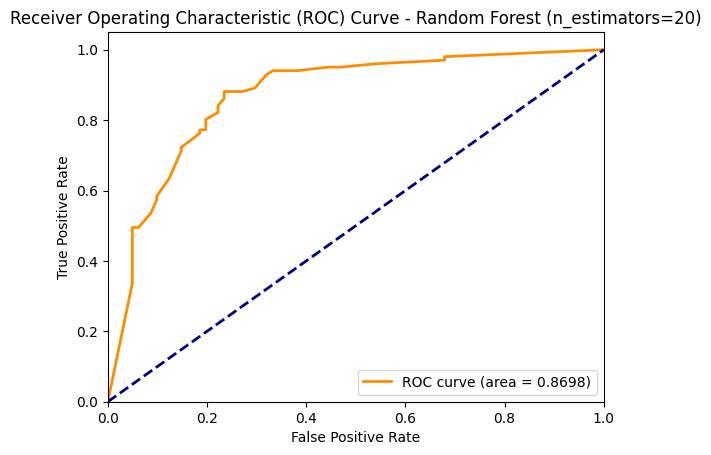

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt

# Inisialisasi model Random Forest dengan 20 pohon
model_rf = RandomForestClassifier(n_estimators=20, random_state=42)

# Latih model menggunakan data training
model_rf.fit(X_train, y_train)

# Lakukan prediksi pada data testing
y_pred_rf = model_rf.predict(X_test)

# Hitung metrik kinerja klasifikasi
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, model_rf.predict_proba(X_test)[:, 1])
auc_rf = auc(fpr_rf, tpr_rf)

# Tampilkan metrik kinerja
print("Metrik Kinerja Model Random Forest (n_estimators=20):")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1 Score: {f1_rf:.4f}")
print(f"AUC-ROC: {auc_rf:.4f}")

# Tampilkan classification report
print("\nClassification Report (n_estimators=20):")
print(classification_report(y_test, y_pred_rf))

# Gambarkan kurva ROC
plt.figure()
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'ROC curve (area = {auc_rf:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Random Forest (n_estimators=20)')
plt.legend(loc="lower right")
plt.show()

**2. Training Model Random Forest (n_estimator = 50)**

Metrik Kinerja Model Random Forest (n_estimators=20):
Accuracy: 0.8077
Precision: 0.8173
Recall: 0.8416
F1 Score: 0.8293
AUC-ROC: 0.8777

Classification Report (n_estimators=20):
              precision    recall  f1-score   support

           0       0.79      0.77      0.78        81
           1       0.82      0.84      0.83       101

    accuracy                           0.81       182
   macro avg       0.81      0.80      0.80       182
weighted avg       0.81      0.81      0.81       182



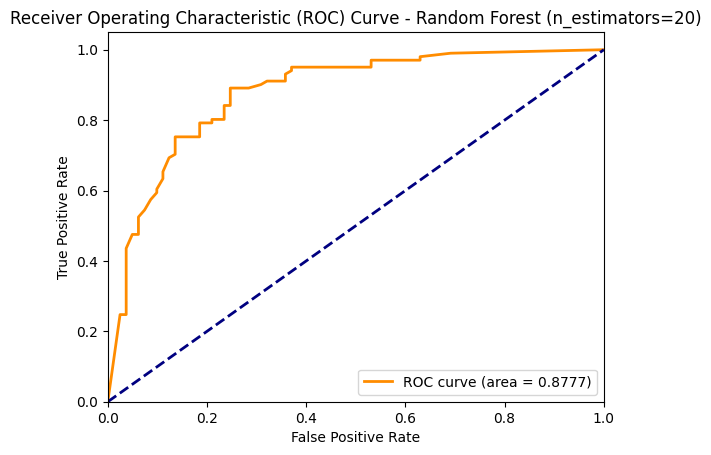

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt

# Inisialisasi model Random Forest dengan 50 pohon
model_rf = RandomForestClassifier(n_estimators=50, random_state=42)

# Latih model menggunakan data training
model_rf.fit(X_train, y_train)

# Lakukan prediksi pada data testing
y_pred_rf = model_rf.predict(X_test)

# Hitung metrik kinerja klasifikasi
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, model_rf.predict_proba(X_test)[:, 1])
auc_rf = auc(fpr_rf, tpr_rf)

# Tampilkan metrik kinerja
print("Metrik Kinerja Model Random Forest (n_estimators=20):")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1 Score: {f1_rf:.4f}")
print(f"AUC-ROC: {auc_rf:.4f}")

# Tampilkan classification report
print("\nClassification Report (n_estimators=20):")
print(classification_report(y_test, y_pred_rf))

# Gambarkan kurva ROC
plt.figure()
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'ROC curve (area = {auc_rf:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Random Forest (n_estimators=20)')
plt.legend(loc="lower right")
plt.show()

# **Pemodelan Logistic Regression**

**Training Model Logistic Regression**

Training Model Losgictic Regression menggunakan X_train dan y_train. Testing Model Losgistic Regression menggunakan X_test dan y_test. Metriks kinerja model: accuracy, precision, recall, F1 score, dan AUC ROC. Tampilkan kurva ROC.

Metrik Kinerja Model Logistic Regression:
Accuracy: 0.8462
Precision: 0.8544
Recall: 0.8713
F1 Score: 0.8627
AUC-ROC: 0.8843

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.81      0.82        81
           1       0.85      0.87      0.86       101

    accuracy                           0.85       182
   macro avg       0.84      0.84      0.84       182
weighted avg       0.85      0.85      0.85       182



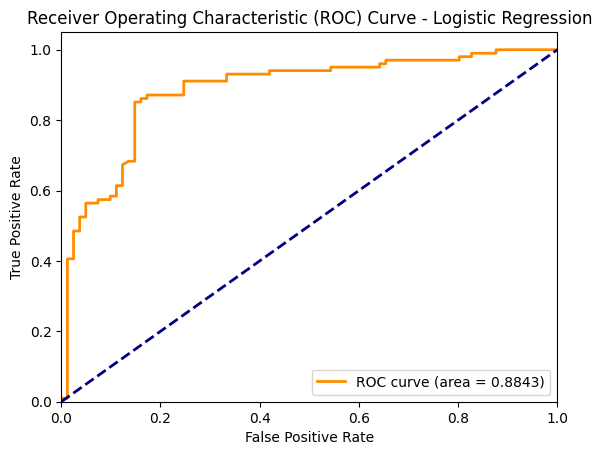

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt

# Inisialisasi model Logistic Regression
model_lr = LogisticRegression(random_state=42)

# Latih model menggunakan data training
model_lr.fit(X_train, y_train)

# Lakukan prediksi pada data testing
y_pred_lr = model_lr.predict(X_test)

# Hitung metrik kinerja klasifikasi
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, model_lr.predict_proba(X_test)[:, 1])
auc_lr = auc(fpr_lr, tpr_lr)

# Tampilkan metrik kinerja
print("Metrik Kinerja Model Logistic Regression:")
print(f"Accuracy: {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall: {recall_lr:.4f}")
print(f"F1 Score: {f1_lr:.4f}")
print(f"AUC-ROC: {auc_lr:.4f}")

# Tampilkan classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Gambarkan kurva ROC
plt.figure()
plt.plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label=f'ROC curve (area = {auc_lr:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Logistic Regression')
plt.legend(loc="lower right")
plt.show()

# **Pemodelan Klasifikasi Menggunakan AUTOML**

In [ ]:
!pip install mljar-supervised

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.6/190.6 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.4/103.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 84.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 19.8 MB/s eta 0:00:00
  Created wheel for mljar-scikit-plot: filename=mljar_scikit_plot-0.3.12-py3-none-any.whl size=32014 sha256=440c05d18a1d103003ca9a90af23d45f3025a2abfa124e6cb1b49c2c929d7696
  Stored in directory: /root/.cache/pip/wheels/24/e5/1e/3b952f43ebd4bd0a6983c835daa4e226f2eeee4080e5b1ceb9
Successfully built mljar-scikit-plot


In [ ]:
from supervised.automl import AutoML
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import warnings

# Ignore specific warnings from matplotlib font manager
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib.font_manager")


# 1. Load dataset
# 2. Inisialisasi AutoML
automl = AutoML(
    mode="Explain",              # mode bisa "Explain", "Perform", "Compete", "Optuna"
    total_time_limit=300,        # waktu total training dalam detik
    eval_metric="accuracy",      # metrik evaluasi
    #algorithms=["LightGBM", "Xgboost", "CatBoost", "RandomForest"],  # algoritma yang digunakan
    algorithms=['Baseline', 'CatBoost', 'Decision Tree', 'Extra Trees', 'Nearest Neighbors', 'LightGBM', 'Linear', "Neural Network", 'Random Forest', 'Xgboost'],
    random_state=42
)

# 3. Latih model
automl.fit(X_train, y_train)

# 4. Prediksi dan evaluasi
y_pred = automl.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))

# 5. Tampilkan leaderboard model
print("Leaderboard model:", automl.get_leaderboard())

AutoML directory: AutoML_1
The task is binary_classification with evaluation metric accuracy
AutoML will use algorithms: ['Baseline', 'CatBoost', 'Decision Tree', 'Extra Trees', 'Nearest Neighbors', 'LightGBM', 'Linear', 'Neural Network', 'Random Forest', 'Xgboost']
AutoML is generating and selecting models automatically. Review outputs before important use.
AutoML will ensemble available models
AutoML steps: ['simple_algorithms', 'default_algorithms', 'ensemble']
* Step simple_algorithms will try to check up to 3 models
1_Baseline accuracy 0.554945 trained in 0.4 seconds


2_DecisionTree accuracy 0.857143 trained in 24.98 seconds


3_Linear accuracy 0.82967 trained in 11.06 seconds
* Step default_algorithms will try to check up to 7 models
4_Default_LightGBM accuracy 0.862637 trained in 10.62 seconds
5_Default_Xgboost accuracy 0.846154 trained in 4.37 seconds
6_Default_CatBoost accuracy 0.873626 trained in 3.87 seconds
7_Default_NeuralNetwork accuracy 0.835165 trained in 2.86 seconds
8_Default_RandomForest accuracy 0.879121 trained in 3.61 seconds
9_Default_ExtraTrees accuracy 0.873626 trained in 3.95 seconds
'KNeighborsAlgorithm' object has no attribute 'classes_'
Problem during computing permutation importance. Skipping ...
10_Default_NearestNeighbors accuracy 0.824176 trained in 2.68 seconds
* Step ensemble will try to check up to 1 model
Ensemble accuracy 0.879121 trained in 2.74 seconds
AutoML fit time: 94.08 seconds
AutoML best model: 8_Default_RandomForest
Akurasi: 0.8296703296703297
Leaderboard model:                            name         model_type metric_type  metric_value  \
0                    1_Ba

In [ ]:
import joblib
import os
import pandas as pd

# Dapatkan leaderboard untuk mengidentifikasi model terbaik
leaderboard = automl.get_leaderboard()

# Dapatkan nama model terbaik dari leaderboard (model dengan metric_value terendah)
best_model_name = leaderboard.iloc[0]['name']

# Filter leaderboard untuk mendapatkan model dasar terbaik (bukan Baseline atau Ensemble)
base_models_leaderboard = leaderboard[~leaderboard['model_type'].isin(['Baseline', 'Ensemble'])]

if not base_models_leaderboard.empty:
    # Dapatkan nama model dasar terbaik
    best_base_model_name = base_models_leaderboard.iloc[0]['name']
    print(f"Model dasar terbaik (selain Ensemble) adalah: {best_base_model_name}")

    # Coba simpan objek AutoML itu sendiri
    try:
        filename_automl_object = 'automl_object.joblib'
        joblib.dump(automl, filename_automl_object)
        print(f"Objek AutoML telah disimpan ke dalam file '{filename_automl_object}'.")
        print("Anda dapat memuat objek ini nanti untuk mengakses model atau hasil.")
    except Exception as e:
        print(f"Gagal menyimpan objek AutoML: {e}")
        print("Mencoba menyimpan model dasar terbaik dari direktori output...")

        model_dir_path = os.path.join('AutoML_2', best_base_model_name)
        # Mencari file model di dalam direktori model
        model_files = [f for f in os.listdir(model_dir_path) if os.path.isfile(os.path.join(model_dir_path, f))]

        if model_files:
            # Ambil file pertama yang ditemukan (ini mungkin perlu disesuaikan)
            model_file_to_save = model_files[0]
            model_file_path = os.path.join(model_dir_path, model_file_to_save)

            try:
                # Muat model dari file
                loaded_model = joblib.load(model_file_path)
                # Tentukan nama file untuk menyimpan ulang
                filename_base_model = f'{best_base_model_name}_model.joblib'
                # Simpan model dasar terbaik ke dalam file
                joblib.dump(loaded_model, filename_base_model)
                print(f"Model dasar terbaik '{best_base_model_name}' telah disimpan ke dalam file '{filename_base_model}'.")
            except Exception as e:
                 print(f"Gagal memuat atau menyimpan model dasar terbaik dari '{model_file_path}': {e}")
                 print("Mungkin format file model tidak didukung oleh joblib atau ada masalah jalur.")

        else:
            print(f"Tidak ada file model yang ditemukan di direktori '{model_dir_path}'.")
            print("Struktur direktori output MLJAR mungkin berbeda dari yang diharapkan.")

else:
    print("Tidak ada model dasar (selain Baseline atau Ensemble) yang ditemukan di leaderboard.")

Model dasar terbaik (selain Ensemble) adalah: 2_DecisionTree
Objek AutoML telah disimpan ke dalam file 'automl_object.joblib'.
Anda dapat memuat objek ini nanti untuk mengakses model atau hasil.


Objek AutoML berhasil dimuat dari 'automl_object.joblib'.

Metrik Kinerja Model Terbaik (dari objek AutoML yang dimuat):
Accuracy: 0.8297
Precision: 0.8241
Recall: 0.8812
F1 Score: 0.8517
AUC-ROC: 0.9037

Classification Report Model Terbaik (dari objek AutoML yang dimuat):
              precision    recall  f1-score   support

           0       0.84      0.77      0.80        81
           1       0.82      0.88      0.85       101

    accuracy                           0.83       182
   macro avg       0.83      0.82      0.83       182
weighted avg       0.83      0.83      0.83       182



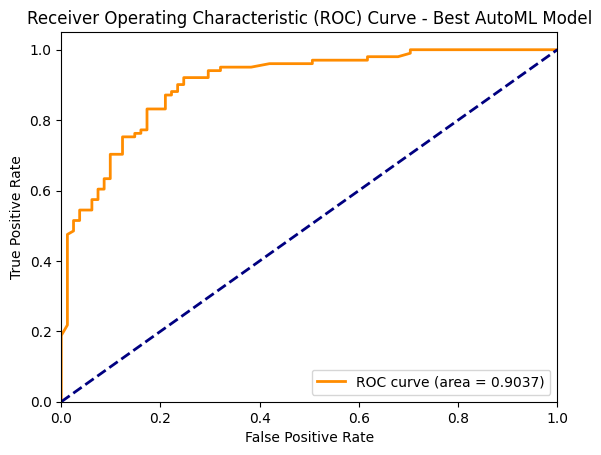

In [ ]:
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt


# Nama file tempat objek AutoML disimpan
filename_automl_object = 'automl_object.joblib'

# Muat objek AutoML dari file
try:
    loaded_automl = joblib.load(filename_automl_object)
    print(f"Objek AutoML berhasil dimuat dari '{filename_automl_object}'.")

    # Lakukan prediksi pada data testing menggunakan objek AutoML yang dimuat
    y_pred_loaded_automl = loaded_automl.predict(X_test)
    y_proba_loaded_automl = loaded_automl.predict_proba(X_test)[:, 1]


    # Hitung metrik kinerja klasifikasi
    accuracy_loaded_automl = accuracy_score(y_test, y_pred_loaded_automl)
    precision_loaded_automl = precision_score(y_test, y_pred_loaded_automl)
    recall_loaded_automl = recall_score(y_test, y_pred_loaded_automl)
    f1_loaded_automl = f1_score(y_test, y_pred_loaded_automl)
    fpr_loaded_automl, tpr_loaded_automl, thresholds_loaded_automl = roc_curve(y_test, y_proba_loaded_automl)
    auc_loaded_automl = auc(fpr_loaded_automl, tpr_loaded_automl)

    # Tampilkan metrik kinerja
    print("\nMetrik Kinerja Model Terbaik (dari objek AutoML yang dimuat):")
    print(f"Accuracy: {accuracy_loaded_automl:.4f}")
    print(f"Precision: {precision_loaded_automl:.4f}")
    print(f"Recall: {recall_loaded_automl:.4f}")
    print(f"F1 Score: {f1_loaded_automl:.4f}")
    print(f"AUC-ROC: {auc_loaded_automl:.4f}")

    # Tampilkan classification report
    print("\nClassification Report Model Terbaik (dari objek AutoML yang dimuat):")
    print(classification_report(y_test, y_pred_loaded_automl))

    # Gambarkan kurva ROC
    plt.figure()
    plt.plot(fpr_loaded_automl, tpr_loaded_automl, color='darkorange', lw=2, label=f'ROC curve (area = {auc_loaded_automl:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve - Best AutoML Model')
    plt.legend(loc="lower right")
    plt.show()


except FileNotFoundError:
    print(f"Error: File '{filename_automl_object}' tidak ditemukan.")
except Exception as e:
    print(f"Terjadi kesalahan saat memuat atau menggunakan objek AutoML: {e}")

In [ ]:
# Evaluate the loaded AutoML model on the training data
y_pred_train_automl = loaded_automl.predict(X_train)
y_proba_train_automl = loaded_automl.predict_proba(X_train)[:, 1]

# Calculate training metrics
accuracy_train_automl = accuracy_score(y_train, y_pred_train_automl)
precision_train_automl = precision_score(y_train, y_pred_train_automl)
recall_train_automl = recall_score(y_train, y_pred_train_automl)
f1_train_automl = f1_score(y_train, y_pred_train_automl)
fpr_train_automl, tpr_train_automl, thresholds_train_automl = roc_curve(y_train, y_proba_train_automl)
auc_train_automl = auc(fpr_train_automl, tpr_train_automl)

print("Metrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TRAINING:")
print(f"Accuracy: {accuracy_train_automl:.4f}")
print(f"Precision: {precision_train_automl:.4f}")
print(f"Recall: {recall_train_automl:.4f}")
print(f"F1 Score: {f1_train_automl:.4f}")
print(f"AUC-ROC: {auc_train_automl:.4f}")

print("\nMetrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TESTING:")
print(f"Accuracy: {accuracy_loaded_automl:.4f}")
print(f"Precision: {precision_loaded_automl:.4f}")
print(f"Recall: {recall_loaded_automl:.4f}")
print(f"F1 Score: {f1_loaded_automl:.4f}")
print(f"AUC-ROC: {auc_loaded_automl:.4f}")

print("\nPerbandingan Kinerja (Training vs Testing):")
print(f"Accuracy Delta (Training - Testing): {accuracy_train_automl - accuracy_loaded_automl:.4f}")
print(f"Precision Delta (Training - Testing): {precision_train_automl - precision_loaded_automl:.4f}")
print(f"Recall Delta (Training - Testing): {recall_train_automl - recall_loaded_automl:.4f}")
print(f"F1 Score Delta (Training - Testing): {f1_train_automl - f1_loaded_automl:.4f}")
print(f"AUC-ROC Delta (Training - Testing): {auc_train_automl - auc_loaded_automl:.4f}")

Metrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TRAINING:
Accuracy: 0.8774
Precision: 0.8598
Recall: 0.9303
F1 Score: 0.8937
AUC-ROC: 0.9387

Metrik Kinerja Model Terbaik (dari objek AutoML yang dimuat) pada DATA TESTING:
Accuracy: 0.8297
Precision: 0.8241
Recall: 0.8812
F1 Score: 0.8517
AUC-ROC: 0.9037

Perbandingan Kinerja (Training vs Testing):
Accuracy Delta (Training - Testing): 0.0477
Precision Delta (Training - Testing): 0.0357
Recall Delta (Training - Testing): 0.0492
F1 Score Delta (Training - Testing): 0.0420
AUC-ROC Delta (Training - Testing): 0.0349
